# EKF 21 · Correcciones de CO₂ sin umbral de flujo

Se compara la regla original de 0,05 g/L/h con una variante que admite cualquier flujo en dos ventanas consecutivas válidas de 30 min. S utiliza el EKF 20 con S 17_2 y el ajuste de Q de crecimiento. G/F utiliza el EKF 18 con G/F 16_2 y el reparto de YAN activo. Cada comparación conserva sus ecuaciones, rampa, matriz Q, R, calibración y entradas. Solo se asimila CO₂.

La comparación principal usa ventanas observadas. En G/F se repite además la comparación con la ventana interpolada del EKF 18 para LAB022–024. En gráficas y métricas principales esa ventana conserva el hueco original. Se mantiene el orden LAB019–021, LAB016–018 y LAB022–024.

Para el modelo S se utiliza el azúcar inicial Y15 en LAB019–024, conservando la calibración S 17_2. LAB016–018 no disponen de Y15 en este soporte: se utiliza la densidad convertida con la nueva fórmula tanto para inicializar como para evaluar el azúcar. Las muestras posteriores de Y15 se superponen como evaluación, sin asimilarlas. La densidad se muestra como referencia independiente con la conversión indicada por el usuario, \(S_\rho=2{,}5(\rho-1000)-16\), con concentraciones en g/L. Se conservan los valores convertidos negativos; no son azúcar físico negativo ni se introducen como estados. Esta ejecución no recalibra parámetros ni cambia las entradas del modelo G/F.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import nbformat
import numpy as np
import pandas as pd

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / "src/wine_fermentation").is_dir())
EKF = ROOT / "notebooks/EKF"
ORDER = ("LAB019", "LAB020", "LAB021", "LAB016", "LAB017", "LAB018",
         "LAB022", "LAB023", "LAB024")
FOCUS = ("LAB023", "LAB024")
WITH_THRESHOLD = "Con umbral"
WITHOUT_THRESHOLD = "Sin umbral"
RULES = (WITH_THRESHOLD, WITHOUT_THRESHOLD)
STYLES = {WITH_THRESHOLD: dict(c="#D55E00", ls="--", zorder=3),
          WITHOUT_THRESHOLD: dict(c="#0072B2", zorder=2)}


def load_reference(number, cells):
    path, = EKF.glob(f"{number}_*.source.ipynb")
    notebook = nbformat.read(path, 4)
    namespace = {"__name__": f"ekf_{number}", "display": lambda *_: None}
    for index in cells:
        source = "\n".join(line for line in notebook.cells[index].source.splitlines()
                           if not line.startswith("%matplotlib"))
        exec(compile(source, f"{path.name} :: cell {index}", "exec"), namespace)
    return namespace


def window_rule(valid):
    valid = np.asarray(valid, dtype=bool)
    return valid & np.r_[False, valid[:-1]]


def validate_base_rule(valid, measured, original):
    np.testing.assert_array_equal(window_rule(valid & (measured >= .05)), original)
    assert np.all(~original | window_rule(valid))


## Modelo S · azúcar inicial Y15 y densidad convertida como referencia

In [2]:
single = load_reference(20, (1, 3, 5))
single_model = single["models"]["Q ajustado"]
def sugar_from_density(density_g_l):
    return 2.5 * (density_g_l - 1000.) - 16.


historical_density = single["v"].density.rename(
    columns={"t_h": "time", "density_g_l": "density"})
recent_density = single["prepared"]["offline"].rename(
    columns={"hours": "time", "Densidad_g_L": "density"})
density_points = {}
density_audit = []
for lab in ORDER:
    inputs = single["data"][lab]
    source = historical_density if lab in single["historical"] else recent_density
    rows = source.loc[source.lab.eq(lab), ["sample", "time", "density"]].dropna(
        subset=["time", "density"]).sort_values("time")
    initial_mask = rows.time.eq(0.) if lab in single["historical"] else rows["sample"].eq("01")
    assert initial_mask.sum() == 1, lab
    initial_density = float(rows.loc[initial_mask, "density"].iloc[0])
    density_s0 = sugar_from_density(initial_density)
    assert density_s0 > 0. and rows.loc[initial_mask, "time"].iloc[0] <= inputs["grid"][0]
    validation = rows.loc[~initial_mask & rows.time.between(inputs["grid"][0], inputs["grid"][-1])]
    assert not validation.empty, lab
    density_points[lab] = dict(
        initial_time=inputs["grid"][0], initial_sugar=density_s0,
        times=validation.time.to_numpy(), sugar=sugar_from_density(validation.density.to_numpy()))
    initial = inputs["initial"].copy()
    previous_s0 = initial[2]
    # LAB019–024: la entrada original del EKF 20 procede de química Y15.
    # LAB016–018: inicializar con la nueva conversión de densidad.
    initial[2] = density_s0 if lab in ("LAB016","LAB017","LAB018") else previous_s0
    np.testing.assert_array_equal(np.delete(initial, 2), np.delete(inputs["initial"], 2))
    single["data"][lab] = {**inputs, "initial": initial}
    density_audit.append({"LAB": lab, "Densidad inicial [g/L]": initial_density,
                          "S inicial utilizado [g/L]": initial[2],
                          "Origen S inicial": "Y15" if lab not in ("LAB016","LAB017","LAB018") else "Densidad: 2,5(ρ−1000)−16",
                          "S inicial por densidad [g/L]": density_s0,
                          "Muestras de validación": len(validation)})
density_audit = pd.DataFrame(density_audit).set_index("LAB")
display(density_audit.round(3))

single_results = {}

for lab in ORDER:
    inputs = single["data"][lab]
    sensor = inputs["sensor"]
    valid = sensor.valid.to_numpy()
    original = sensor["update"].to_numpy()
    validate_base_rule(valid, sensor.measured.to_numpy(), original)
    for label in RULES:
        updates = original if label == WITH_THRESHOLD else window_rule(valid)
        run_inputs = {**inputs, "sensor": sensor.assign(update=updates)}
        states, readings = single["replay"](run_inputs, single_model)
        single_results[lab, label] = (states, readings)
        print("S", lab, label, flush=True)
    np.testing.assert_array_equal(single_results[lab, WITH_THRESHOLD][0][:, 1],
                                  single_results[lab, WITHOUT_THRESHOLD][0][:, 1])


kLa y ganancia: 0.13796553316180868 0.6586783889606775
S LAB019 Con umbral
S LAB019 Sin umbral
S LAB020 Con umbral
S LAB020 Sin umbral
S LAB021 Con umbral
S LAB021 Sin umbral
S LAB016 Con umbral
S LAB016 Sin umbral
S LAB017 Con umbral
S LAB017 Sin umbral
S LAB018 Con umbral
S LAB018 Sin umbral
S LAB022 Con umbral
S LAB022 Sin umbral
S LAB023 Con umbral
S LAB023 Sin umbral
S LAB024 Con umbral
S LAB024 Sin umbral


,Densidad inicial [g/L],S inicial utilizado [g/L],Origen S inicial,S inicial por densidad [g/L],Muestras de validación
LAB,,,,,
LAB019,1067.6,158.16,Y15,153.00,11
LAB020,1068.5,157.46,Y15,155.25,11
LAB021,1066.8,161.23,Y15,151.00,11
LAB016,1069.0,156.50,"Densidad: 2,5(ρ−1000)−16",156.50,8
LAB017,1069.0,156.50,"Densidad: 2,5(ρ−1000)−16",156.50,8
LAB018,1069.0,156.50,"Densidad: 2,5(ρ−1000)−16",156.50,8
LAB022,1068.6,150.03,Y15,155.50,5
LAB023,1068.2,150.92,Y15,154.50,5
LAB024,1068.0,149.75,Y15,154.00,5


## Modelo G/F · configuración del EKF 18 con reparto de YAN

In [3]:
dual = load_reference(18, (2, 4, 5, 7, 8))
dual_results, dual_interpolated = {}, {}
for lab in ORDER:
    cases = {name: dual["data"][lab][name]
             for name in ("Sin rellenar", "Interpolado")} if lab in dual["labs"] else {
                 "Observado": dual["DATA"][lab]}
    for case, inputs in cases.items():
        grid = inputs["grid"]
        on_half_hour = (grid > 0.) & np.isclose(grid * 2, np.round(grid * 2), rtol=0, atol=1e-8)
        valid = inputs["valid"][on_half_hour]
        original = inputs["update"][on_half_hour]
        validate_base_rule(valid, inputs["y"][on_half_hour], original)
        new_rule = np.zeros_like(inputs["update"])
        new_rule[on_half_hour] = window_rule(valid)
        assert not np.any(inputs["update"] & ~new_rule)
        runs = dual_interpolated if case == "Interpolado" else dual_results
        for label in RULES:
            update = inputs["update"] if label == WITH_THRESHOLD else new_rule
            outputs = dual["replay"]({**inputs, "update": update}, partition_yan=True)
            runs[lab, label] = (inputs, outputs)
            print("G/F", lab, case, label, flush=True)


Kernel fermentation · SciPy 1.13.1
Química 16_2 · Y_X/N = 5.27236800 g/g
G/F LAB019 Observado Con umbral
G/F LAB019 Observado Sin umbral
G/F LAB020 Observado Con umbral
G/F LAB020 Observado Sin umbral
G/F LAB021 Observado Con umbral
G/F LAB021 Observado Sin umbral
G/F LAB016 Observado Con umbral
G/F LAB016 Observado Sin umbral
G/F LAB017 Observado Con umbral
G/F LAB017 Observado Sin umbral
G/F LAB018 Observado Con umbral
G/F LAB018 Observado Sin umbral
G/F LAB022 Sin rellenar Con umbral
G/F LAB022 Sin rellenar Sin umbral
G/F LAB022 Interpolado Con umbral
G/F LAB022 Interpolado Sin umbral
G/F LAB023 Sin rellenar Con umbral
G/F LAB023 Sin rellenar Sin umbral
G/F LAB023 Interpolado Con umbral
G/F LAB023 Interpolado Sin umbral
G/F LAB024 Sin rellenar Con umbral
G/F LAB024 Sin rellenar Sin umbral
G/F LAB024 Interpolado Con umbral
G/F LAB024 Interpolado Sin umbral


mu0         0.086722
betaG0      0.428291
betaF0      0.593521
Kn0         0.008258
Kg0         4.400775
Kf0        19.296084
Kig0       80.490799
Kie0      168.120412
Kd0         0.000440
Yxn         5.272368
Yxg         0.966094
Yxf         1.109896
Yeg         0.459547
Yef         0.510598
m0          0.018339
Name: Parámetros químicos del 16_2, dtype: float64

,X inicial [g/L],YAN inicial [mg/L],G inicial [g/L],F inicial [g/L],Volumen a 22 h [L],Horizonte [h],CO₂ interpolado [g/(L h)],Correcciones con CSV,Correcciones sin rellenar,Horas de corrección añadidas
LAB,,,,,,,,,,
LAB022,0.1809,248.535,77.36,72.67,1.95,190.0,0.0363,247,247,—
LAB023,0.3191,244.535,76.77,74.15,1.95,190.0,0.0753,295,294,22.5
LAB024,0.4056,244.535,75.54,74.21,1.95,190.0,0.0849,254,253,22.5


,Hora local,Hora desde inoculación [h],Volumen [L],Pulso nominal [mg N/L]
LAB022,2026-11-09 10:53:00,113.633,1.85,99.906
LAB023,2026-11-09 11:02:00,113.783,1.85,99.906
LAB024,2026-11-09 11:08:00,113.883,1.85,99.906


## Variables y observaciones

In [4]:
SYMBOLS = {
    "X": ("Biomasa viable", "g/L"), "N": ("YAN", "mg N/L"),
    "S": ("Azúcar total S", "g/L"), "GF": ("G+F", "g/L"),
    "G": ("Glucosa", "g/L"), "F": ("Fructosa", "g/L"),
    "E": ("Etanol", "g/L"), "CO2": ("Flujo de CO₂", "g/L/h"),
}
VARIABLES = {"S": ("X", "N", "S", "E", "CO2"),
             "G/F": ("X", "N", "G", "F", "GF", "E", "CO2")}
RECENT_COLUMNS = {"N": "YAN for plot", "GF": "GLU-FRU-320",
                  "G": "GLUCOSE-320", "F": "Fructose (derived)"}


def normalize_single(lab, label):
    states, readings = single_results[lab, label]
    inputs = single["data"][lab]
    x, n, s, e = (states[:, 0, :4] * single["SCALE_EKF"][:4]).T
    return dict(time=inputs["grid"], pulse=list(inputs["pulses"]),
                states={"X": x, "N": n * 1000., "S": s, "E": e},
                gas=readings.rename(columns={"t_h": "time"}))


def normalize_dual(lab, label, *, interpolated=False):
    runs = dual_interpolated if interpolated else dual_results
    inputs, ((states, _, diag), yan, _, _) = runs[lab, label]
    grid = inputs["grid"]
    mask = np.isfinite(diag[:, 0])
    x, n, g, f, e = states[:, :5].T
    gas = pd.DataFrame(dict(time=grid[mask], measured=inputs["y"][mask],
                            valid=inputs["valid"][mask], forecast=diag[mask, 0],
                            update=diag[mask, 5] == 1, delta_yan_mg_L=yan[mask, 1]))
    return dict(time=grid, pulse=grid[inputs["doses"] > 0],
                states={"X": x, "N": n * 1000., "G": g, "F": f, "GF": g + f, "E": e},
                gas=gas)


TRAJECTORIES = {(model, lab, label): normalize(lab, label)
                for model, normalize in (("S", normalize_single), ("G/F", normalize_dual))
                for lab in ORDER for label in RULES}


def lab_samples(model, lab, variable):
    if variable == "S":
        if lab in ("LAB016","LAB017","LAB018"):
            density = density_points[lab]
            return density["times"], density["sugar"]
        if lab in single["historical"]:
            samples = single["chemical_observations"](single["v"].chem, lab, "GF")
            times = samples.t_h.to_numpy()
            values = samples[single["CHEMICAL_COLUMNS"]["GF"]].to_numpy()
        else:
            samples = single["holdout_chemistry"]
            samples = samples.loc[samples.lab.eq(lab)].dropna(subset=["GLU-FRU-320"])
            times, values = samples.hours.to_numpy(), samples["GLU-FRU-320"].to_numpy()
        grid = single["data"][lab]["grid"]
        valid = (times >= 0.) & (times <= grid[-1]) & np.isfinite(values)
        return times[valid], values[valid]
    chemical_state = variable
    if model == "S" and variable == "X":
        samples = single["scoring_samples"][lab]
        times=samples.t_h.to_numpy();values=samples.X_viable_g_l.to_numpy()
        t0=single["data"][lab]["grid"][0]
        if not np.isclose(times,t0).any():
            times=np.r_[t0,times];values=np.r_[single["data"][lab]["initial"][0],values]
        return times,values
    if lab in dual["labs"]:
        if variable == "X":
            samples = dual["biomass"]
            samples = samples.loc[samples.lab.eq(lab)]
            return samples.hours, samples.X_g_L
        if chemical_state not in RECENT_COLUMNS:
            return [], []
        samples = single["holdout_chemistry"] if model == "S" else dual["chemistry"]
        name = RECENT_COLUMNS[chemical_state]
        samples = samples.loc[samples.lab.eq(lab)].dropna(subset=[name])
        return samples.hours, samples[name]
    scale = 1000. if variable == "N" else 1.
    if model == "S":
        samples = single["chemical_observations"](single["v"].chem, lab, chemical_state)
        samples = samples.loc[samples.t_h.ge(0.) & samples.t_h.le(single["data"][lab]["grid"][-1])]
        return samples.t_h, scale * samples[single["CHEMICAL_COLUMNS"][chemical_state]]
    name = dual["core"].CHEM_COLS.get(chemical_state)
    if name is None or name not in dual["CHEM"]:
        return [], []
    samples = dual["CHEM"]
    samples = samples.loc[samples.lab.eq(lab) & samples.t_h.ge(0.) &
                          samples.t_h.le(dual["DATA"][lab]["horizon"])].dropna(subset=[name])
    if chemical_state == "GF":
        samples = samples.loc[~samples.GF_zero_substitution.astype(str).str.lower().eq("true")]
    return samples.t_h, scale * samples[name]


## Inicio de corrección y cola de CO₂

El salto es la diferencia de YAN justo antes y después de una corrección, sin incluir la propagación ni el pulso. Se informa la primera corrección, la primera con un cambio de al menos 1 mg N/L y la mayor corrección individual de las primeras 40 h. Se evalúa el pronóstico de CO₂ previo a la corrección en ventanas observadas válidas desde 1 h, con una métrica adicional desde 130 h. El último cruce de 0,05 se usa como métrica de duración en ambas corridas.

In [5]:
def metrics_row(run, observed):
    time, states = run["time"], run["states"]
    gas = run["gas"]
    np.testing.assert_array_equal(gas.time.to_numpy(), observed.time.to_numpy())
    first = gas.loc[gas["update"]].iloc[0]
    effective = gas.loc[gas["update"] & gas.delta_yan_mg_L.abs().ge(1.)]
    early = gas.loc[gas["update"] & gas.time.le(40.)]
    peak = early.loc[early.delta_yan_mg_L.abs().idxmax()] if len(early) else None
    valid = observed.valid & observed.time.ge(1.)
    tail = valid & observed.time.ge(130.)
    error = gas.forecast - observed.measured
    start_tail = np.flatnonzero((time > max(run["pulse"])) & (states["N"] <= 1.))
    return {
        "Primera corrección [h]": first.time,
        "ΔYAN primera corrección [mg N/L]": first.delta_yan_mg_L,
        "Primer abs(ΔYAN) ≥1 [h]": effective.time.min(),
        "Mayor ΔYAN hasta 40 h [mg N/L]": peak.delta_yan_mg_L if peak is not None else np.nan,
        "Hora del mayor salto [h]": peak.time if peak is not None else np.nan,
        "Correcciones": int(gas["update"].sum()),
        "RMSE CO₂ [g/L/h]": np.sqrt(np.mean(error[valid] ** 2)),
        "RMSE CO₂ desde 130 h [g/L/h]": np.sqrt(np.mean(error[tail] ** 2)),
        "Ventanas de cola": int(tail.sum()),
        "Última hora CO₂ pronosticado ≥0,05": gas.loc[valid & gas.forecast.ge(.05), "time"].max(),
        "Última hora CO₂ medido ≥0,05": observed.loc[valid & observed.measured.ge(.05), "time"].max(),
        "Máximo YAN tras llegar a ≤1 pospulso [mg N/L]":
            states["N"][start_tail[0]:].max() if len(start_tail) else np.nan,
    }


rows = []
for model in VARIABLES:
    for lab in ORDER:
        observed = TRAJECTORIES[model, lab, WITH_THRESHOLD]["gas"]
        for rule in RULES:
            run = TRAJECTORIES[model, lab, rule]
            rows.append(dict(Modelo=model, LAB=lab, Regla=rule, **metrics_row(run, observed)))
metrics = pd.DataFrame(rows).set_index(["Modelo", "LAB", "Regla"])
focus = metrics.loc[(slice(None), list(FOCUS), slice(None)), :]
display(focus.round(4))
print(focus.round(4).to_string())
display(metrics.round(4))

sensitivity = []
for lab in dual["labs"]:
    observed = TRAJECTORIES["G/F", lab, WITH_THRESHOLD]["gas"]
    for rule in RULES:
        run = normalize_dual(lab, rule, interpolated=True)
        sensitivity.append(dict(LAB=lab, Regla=rule, **metrics_row(run, observed)))
print("G/F con la ventana interpolada del EKF 18; puntuación sobre las ventanas observadas.")
display(pd.DataFrame(sensitivity).set_index(["LAB", "Regla"]).round(4))


                          Primera corrección [h]  ΔYAN primera corrección [mg N/L]  Primer abs(ΔYAN) ≥1 [h]  Mayor ΔYAN hasta 40 h [mg N/L]  Hora del mayor salto [h]  Correcciones  RMSE CO₂ [g/L/h]  RMSE CO₂ desde 130 h [g/L/h]  Ventanas de cola  Última hora CO₂ pronosticado ≥0,05  Última hora CO₂ medido ≥0,05  Máximo YAN tras llegar a ≤1 pospulso [mg N/L]
Modelo LAB    Regla                                                                                                                                                                                                                                                                                                                                                   
S      LAB023 Con umbral                    23.0                           30.5211                     23.0                         30.5211                      23.0           294            0.1340                        0.0841               121                               118.5 

Primera corrección [h]  ...  Máximo YAN tras llegar a ≤1 pospulso [mg N/L]
Modelo LAB    Regla                               ...                                               
S      LAB023 Con umbral                    23.0  ...                                         0.9452
              Sin umbral                     1.5  ...                                       148.4452
G/F    LAB023 Con umbral                    23.0  ...                                         0.9248
              Sin umbral                     1.0  ...                                         0.8676
S      LAB024 Con umbral                    23.0  ...                                         0.0000
              Sin umbral                     1.5  ...                                            NaN
G/F    LAB024 Con umbral                    23.0  ...                                         0.9387
              Sin umbral                     1.0  ...                                         0.9763

[8 rows x 12 columns]

Primera corrección [h]  ...  Máximo YAN tras llegar a ≤1 pospulso [mg N/L]
Modelo LAB    Regla                               ...                                               
S      LAB019 Con umbral                    16.5  ...                                         0.9220
              Sin umbral                     1.0  ...                                         0.9762
       LAB020 Con umbral                    30.5  ...                                         0.8899
              Sin umbral                     1.0  ...                                         0.8691
       LAB021 Con umbral                    16.0  ...                                         0.9875
              Sin umbral                     1.0  ...                                         0.7624
       LAB016 Con umbral                    10.0  ...                                         0.9620
              Sin umbral                     1.0  ...                                         0.8245
       LAB017 Con umbral                    17.5  ...                                         0.7600
              Sin umbral                     1.0  ...                                         0.9728
       LAB018 Con umbral                    12.0  ...                                         0.9753
              Sin umbral                     1.0  ...                                         0.9829
       LAB022 Con umbral                    64.0  ...                                         0.8720
              Sin umbral                     1.5  ...                                         0.9005
       LAB023 Con umbral                    23.0  ...                                         0.9452
              Sin umbral                     1.5  ...                                       148.4452
       LAB024 Con umbral                    23.0  ...                                         0.0000
              Sin umbral                     1.5  ...                                            NaN
G/F    LAB019 Con umbral                    16.5  ...                                         0.9753
              Sin umbral                     1.0  ...                                         0.9884
       LAB020 Con umbral                    30.5  ...                                         0.9926
              Sin umbral                     1.0  ...                                         0.9349
       LAB021 Con umbral                    16.0  ...                                         0.8559
              Sin umbral                     1.0  ...                                         0.8599
       LAB016 Con umbral                    10.0  ...                                         0.9687
              Sin umbral                     1.0  ...                                         0.9070
       LAB017 Con umbral                    17.5  ...                                         0.9481
              Sin umbral                     1.0  ...                                         0.9430
       LAB018 Con umbral                    12.0  ...                                         0.9654
              Sin umbral                     1.0  ...                                         0.8482
       LAB022 Con umbral                    64.0  ...                                         0.9318
              Sin umbral                     1.0  ...                                         0.9009
       LAB023 Con umbral                    23.0  ...                                         0.9248
              Sin umbral                     1.0  ...                                         0.8676
       LAB024 Con umbral                    23.0  ...                                         0.9387
              Sin umbral                     1.0  ...                                         0.9763

[36 rows x 12 columns]

Primera corrección [h]  ...  Máximo YAN tras llegar a ≤1 pospulso [mg N/L]
LAB    Regla                               ...                                               
LAB022 Con umbral                    64.0  ...                                         0.9318
       Sin umbral                     1.0  ...                                         0.9009
LAB023 Con umbral                    22.5  ...                                         0.9363
       Sin umbral                     1.0  ...                                         0.9836
LAB024 Con umbral                    22.5  ...                                         0.9426
       Sin umbral                     1.0  ...                                         0.9590

[6 rows x 12 columns]

## Curvas de los nueve lotes

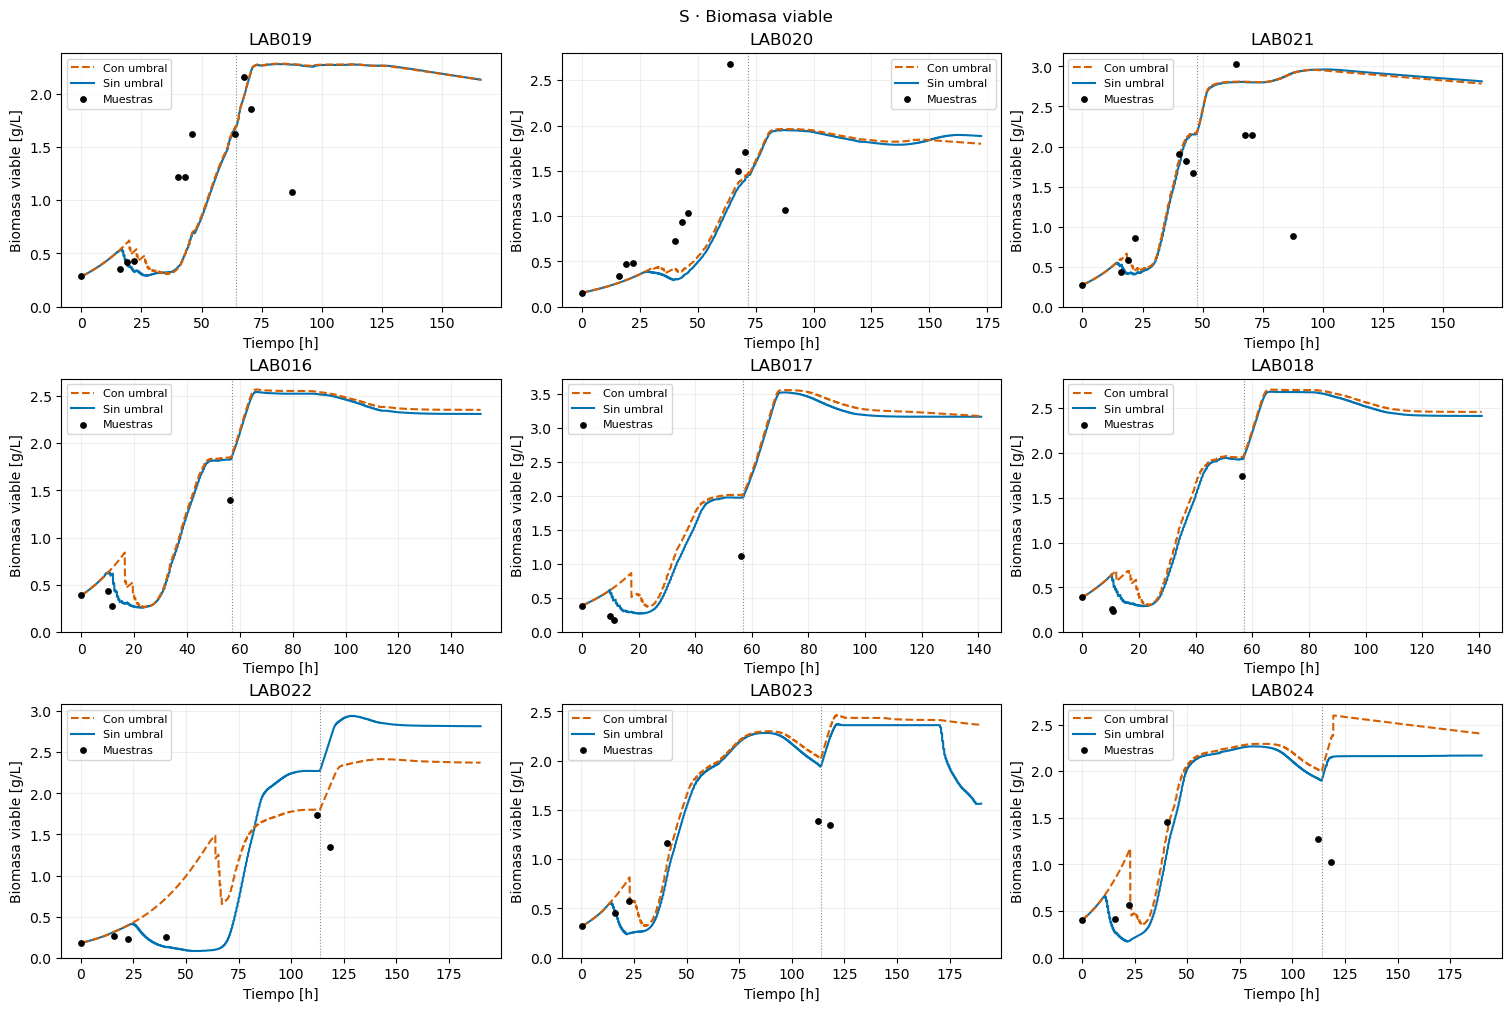

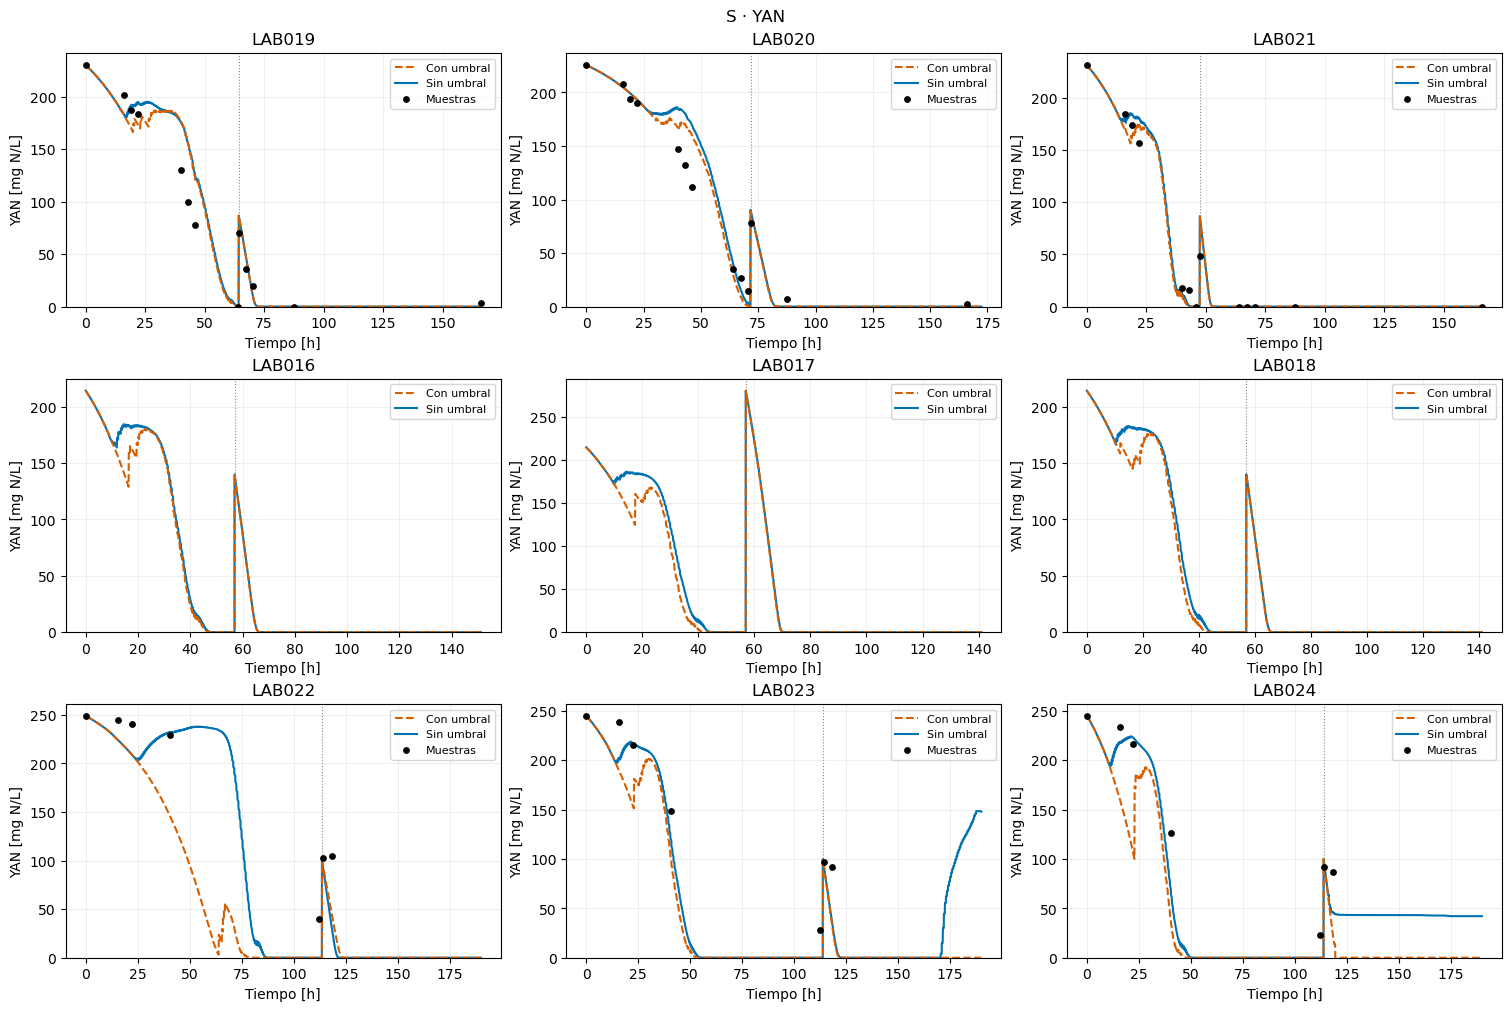

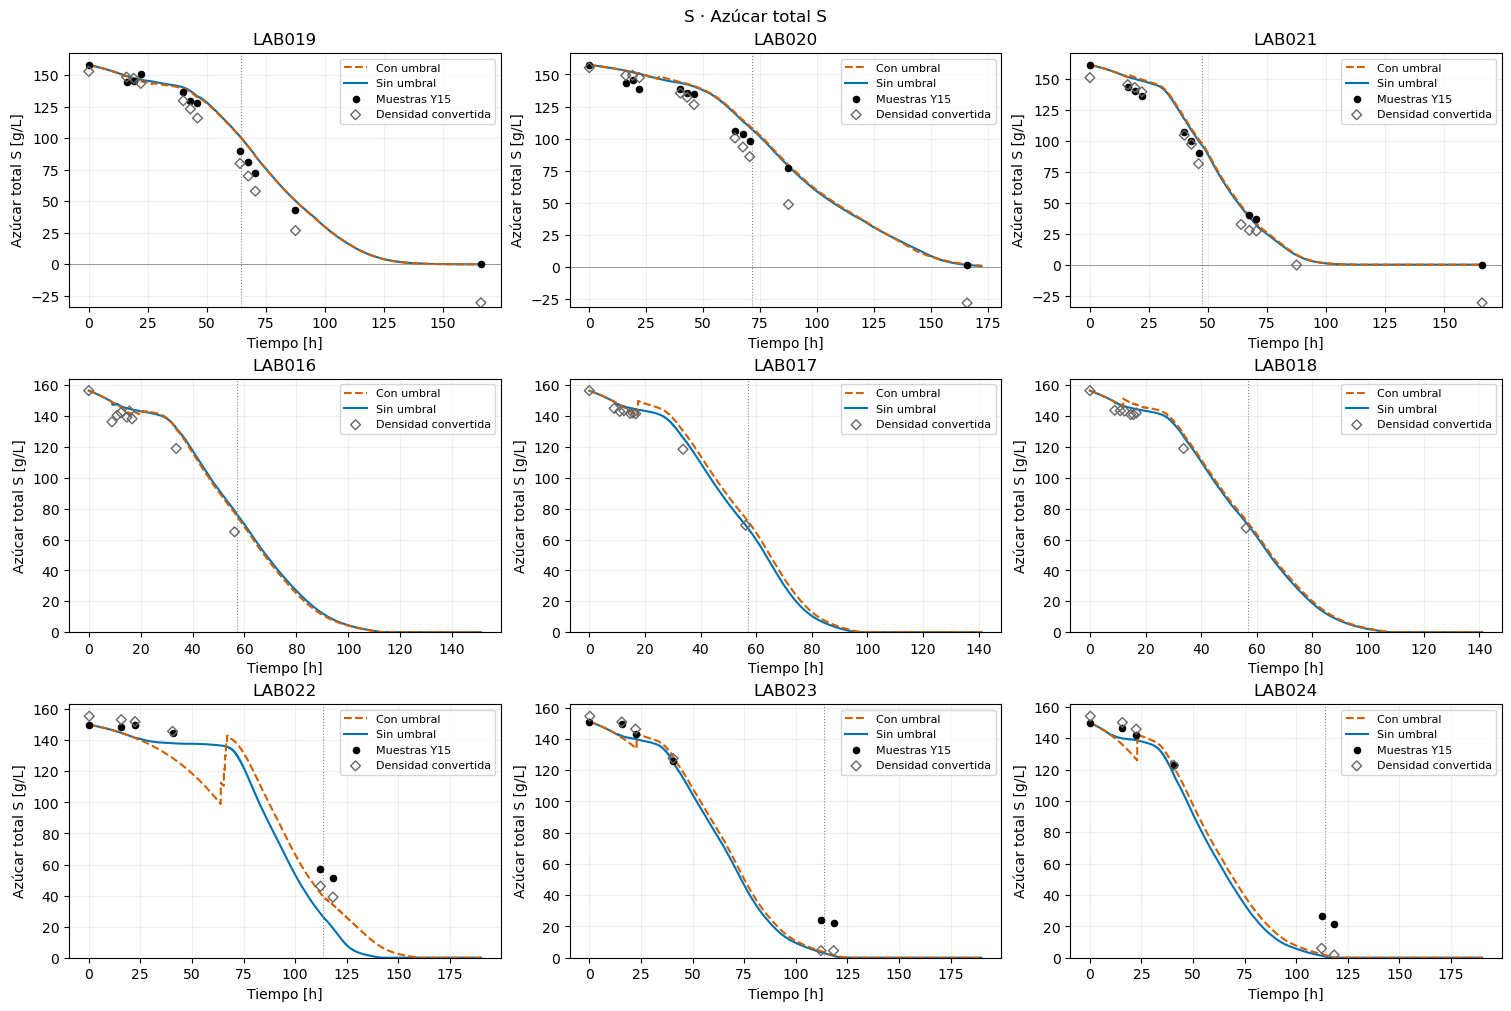

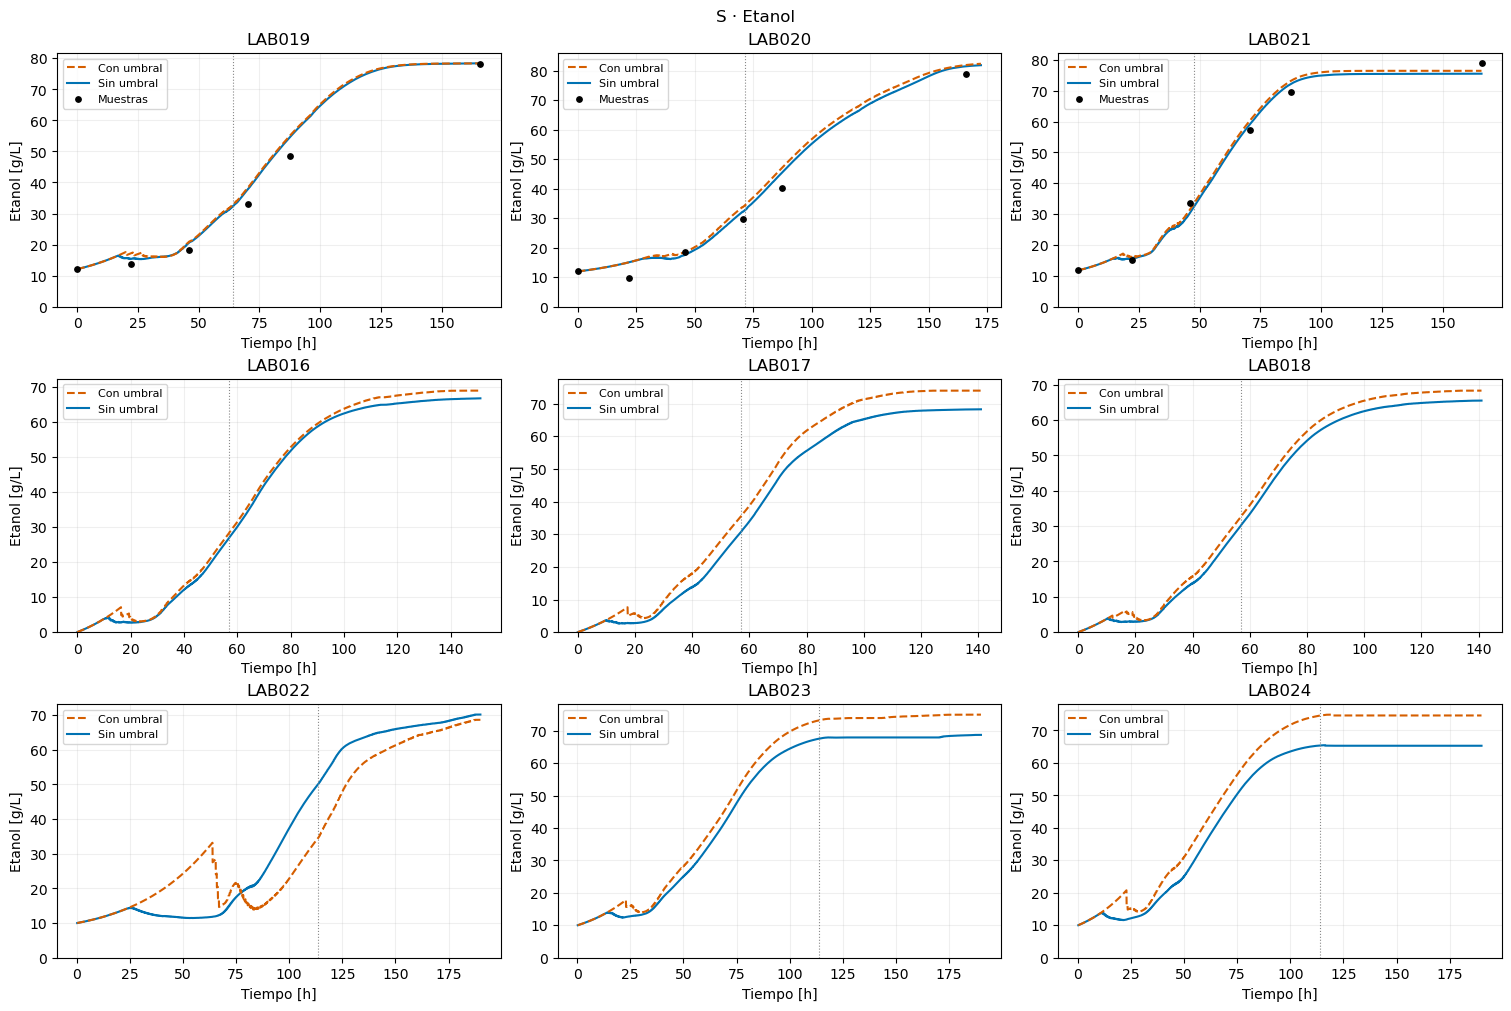

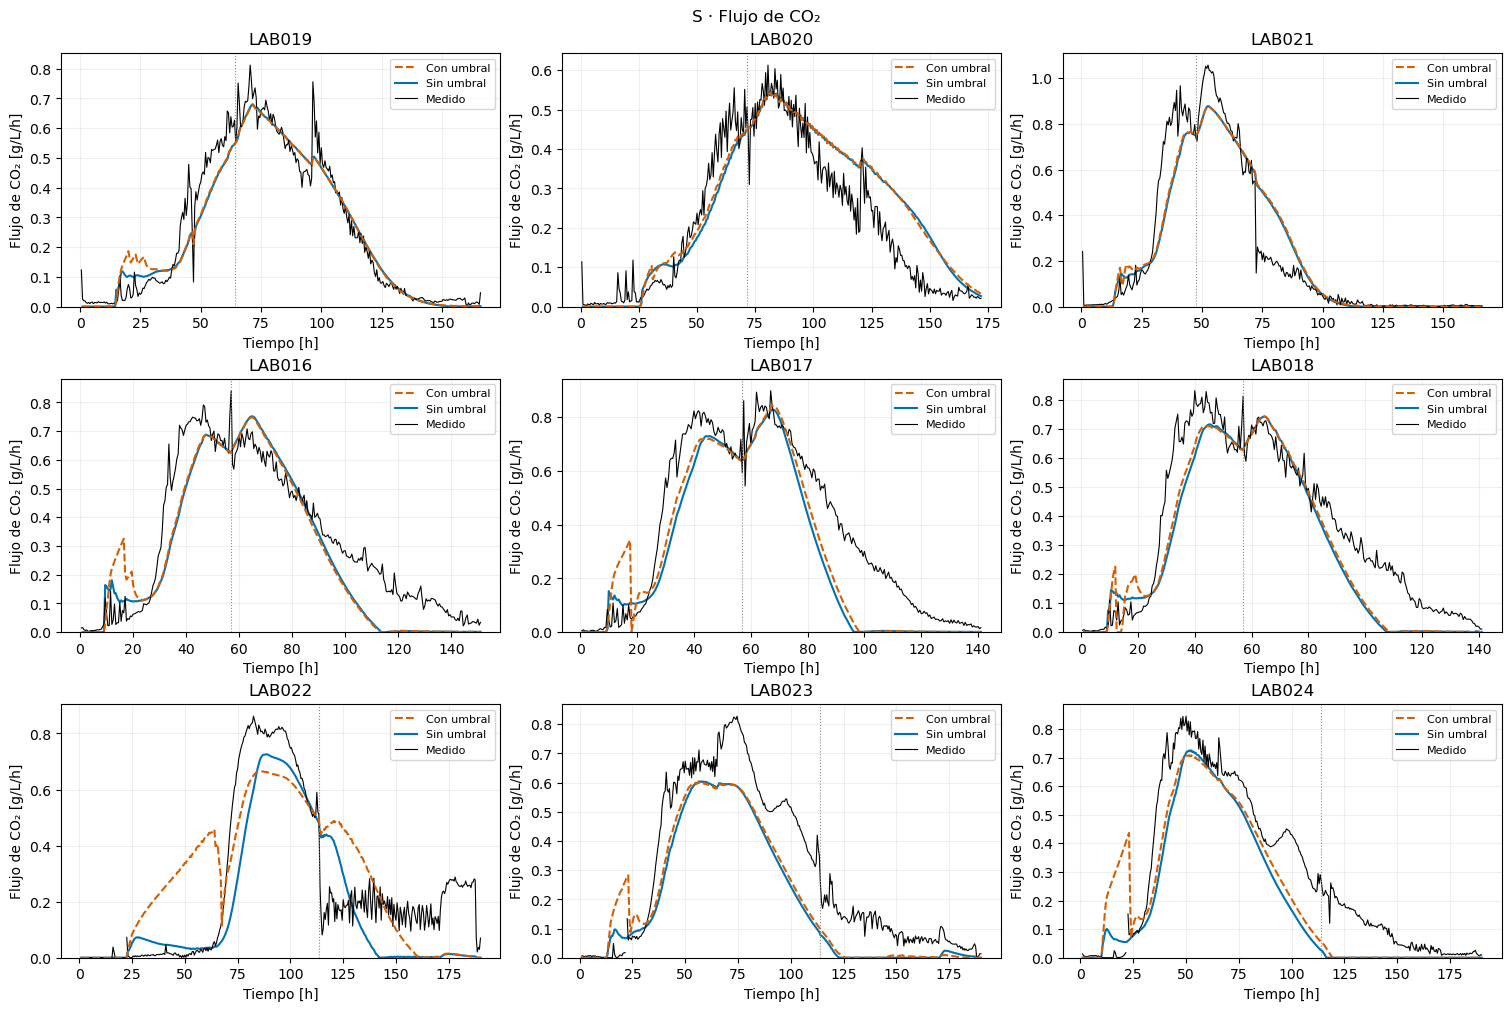

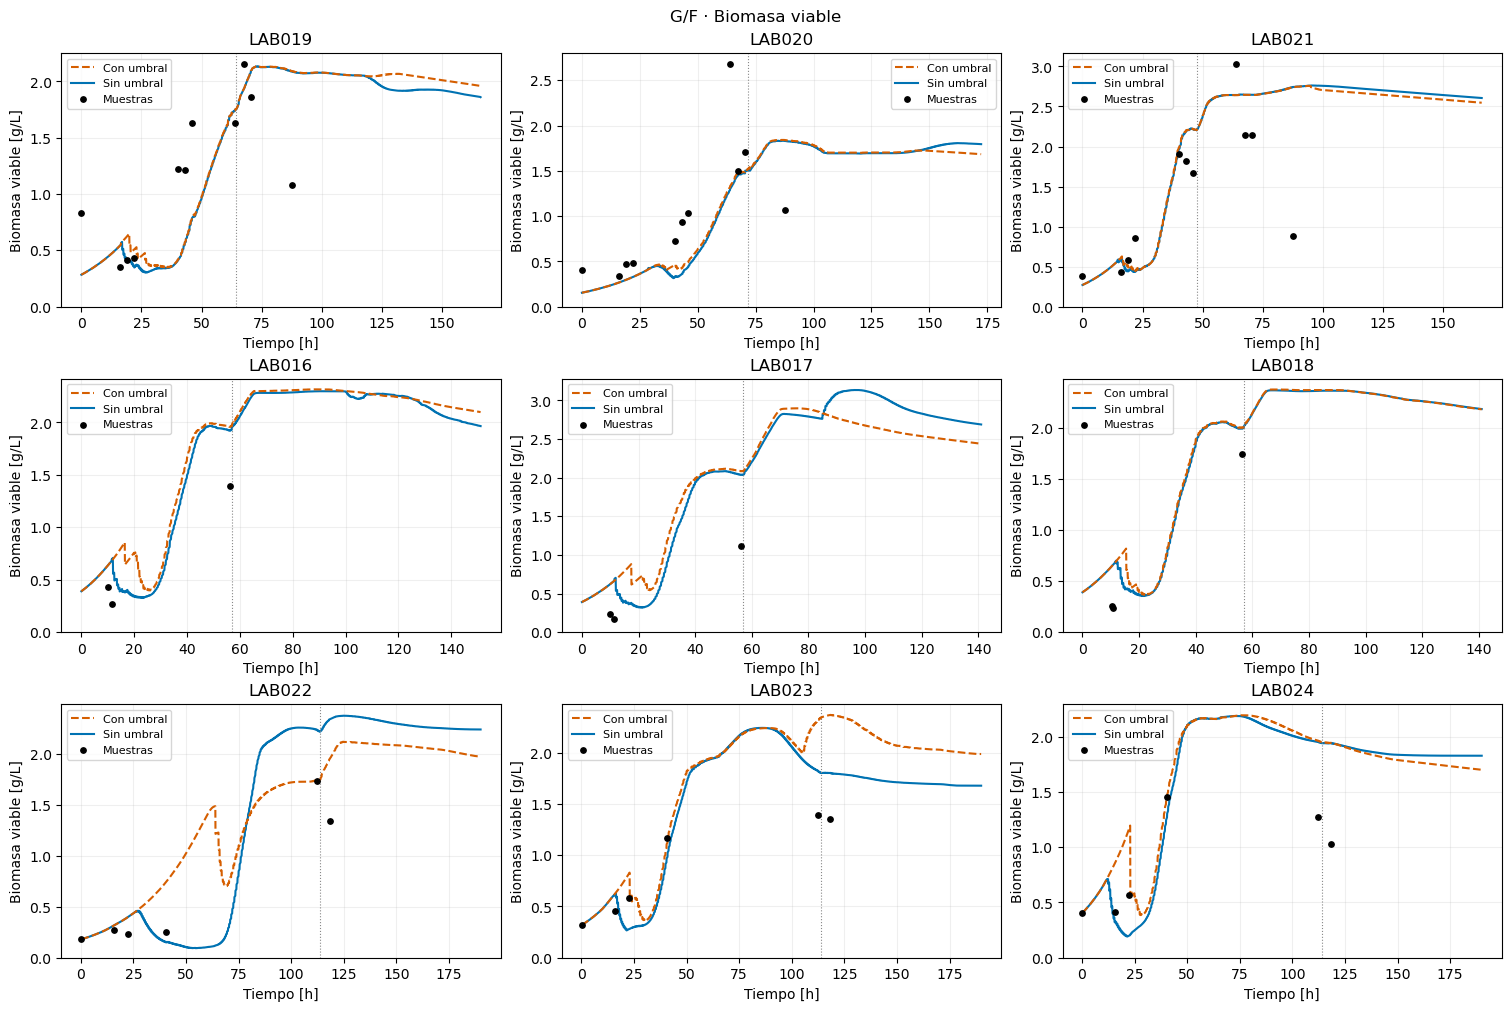

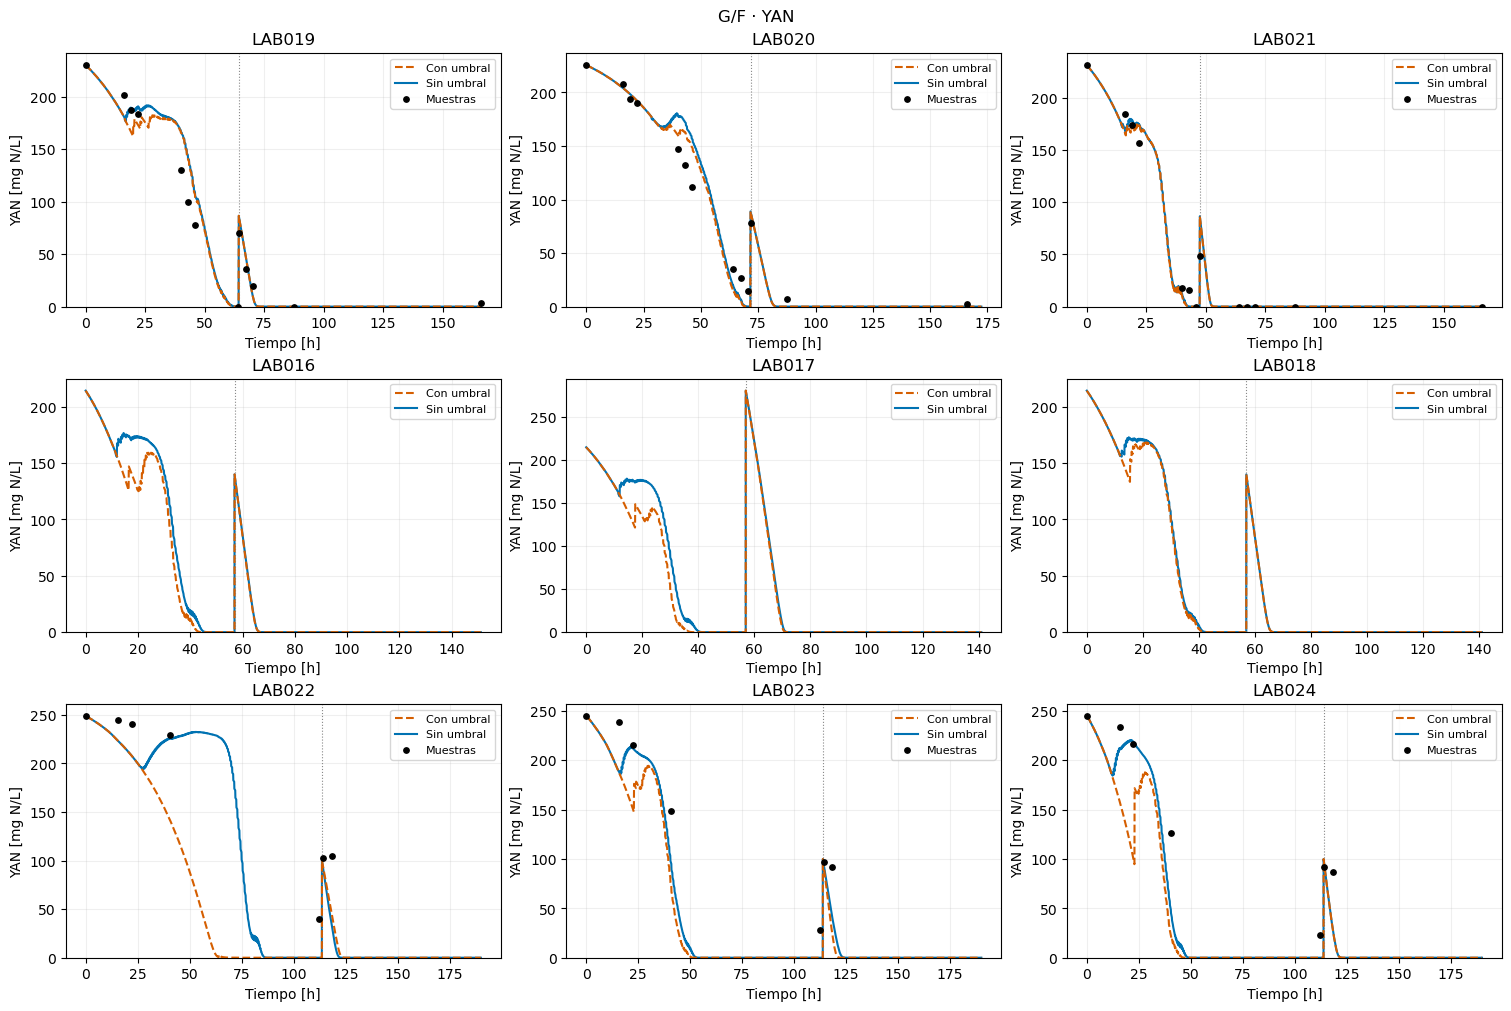

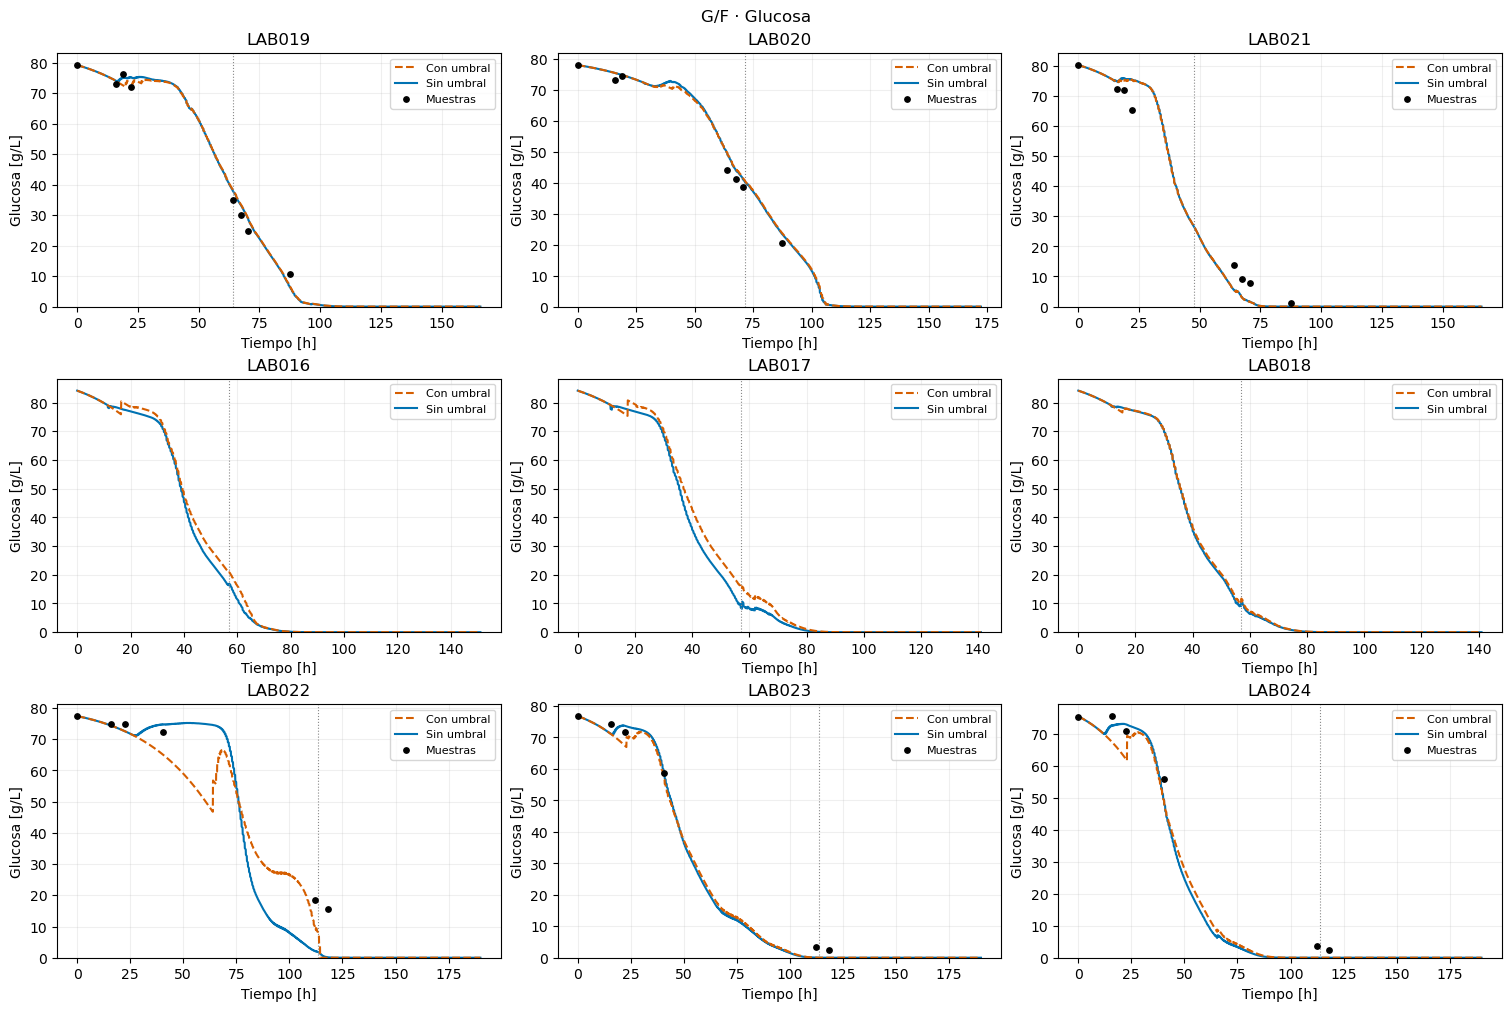

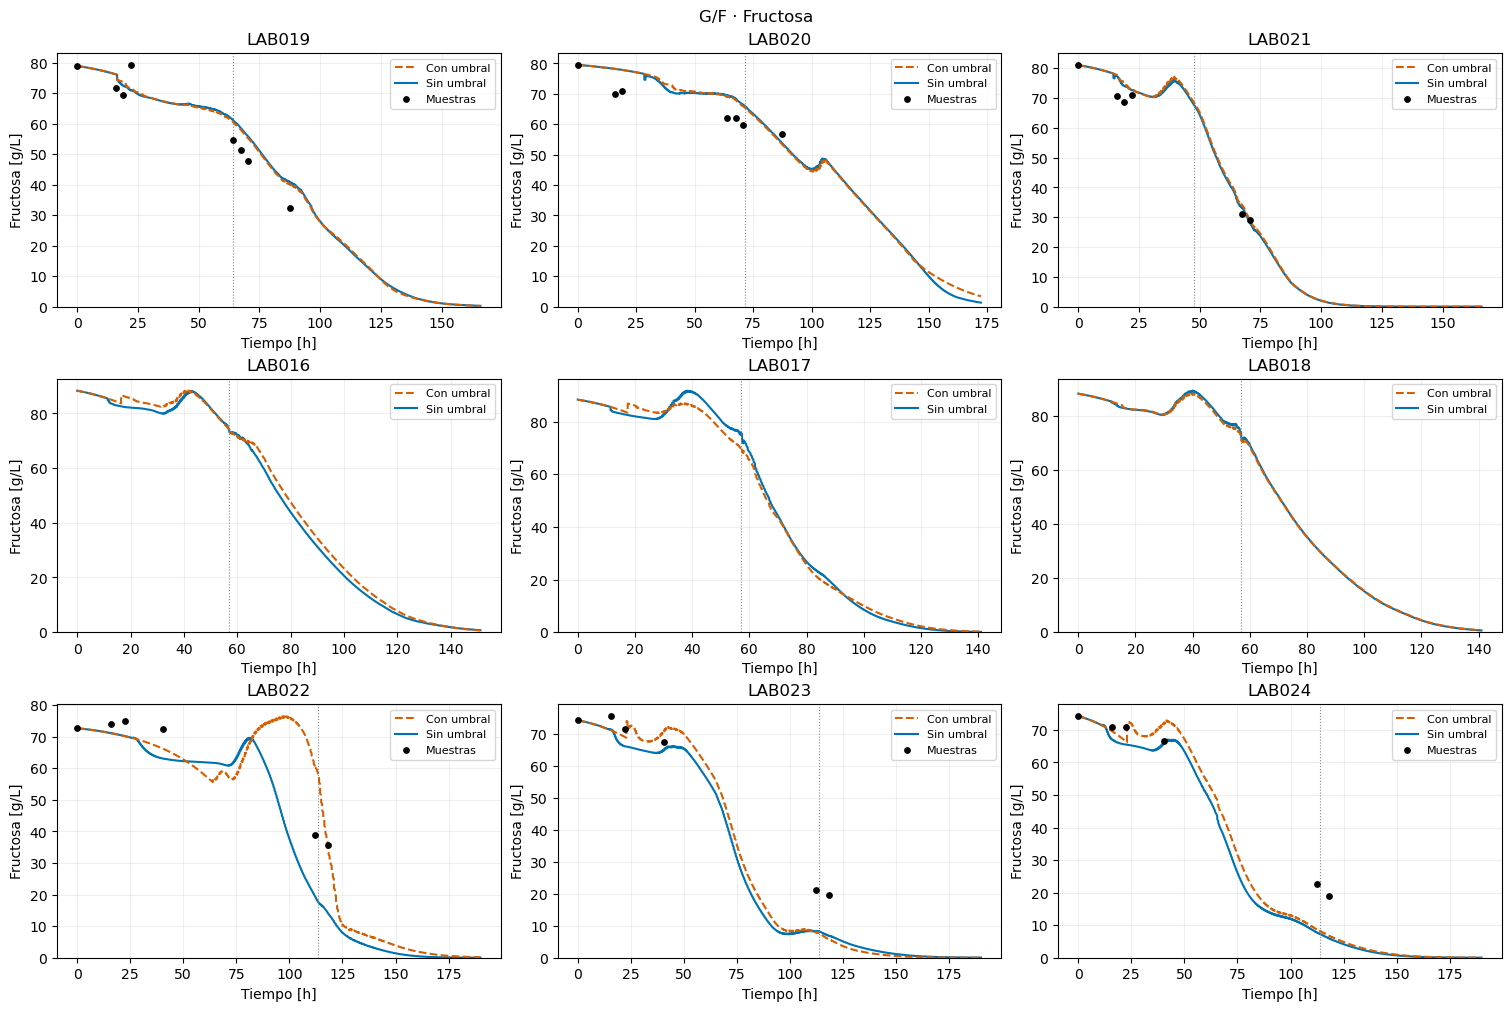

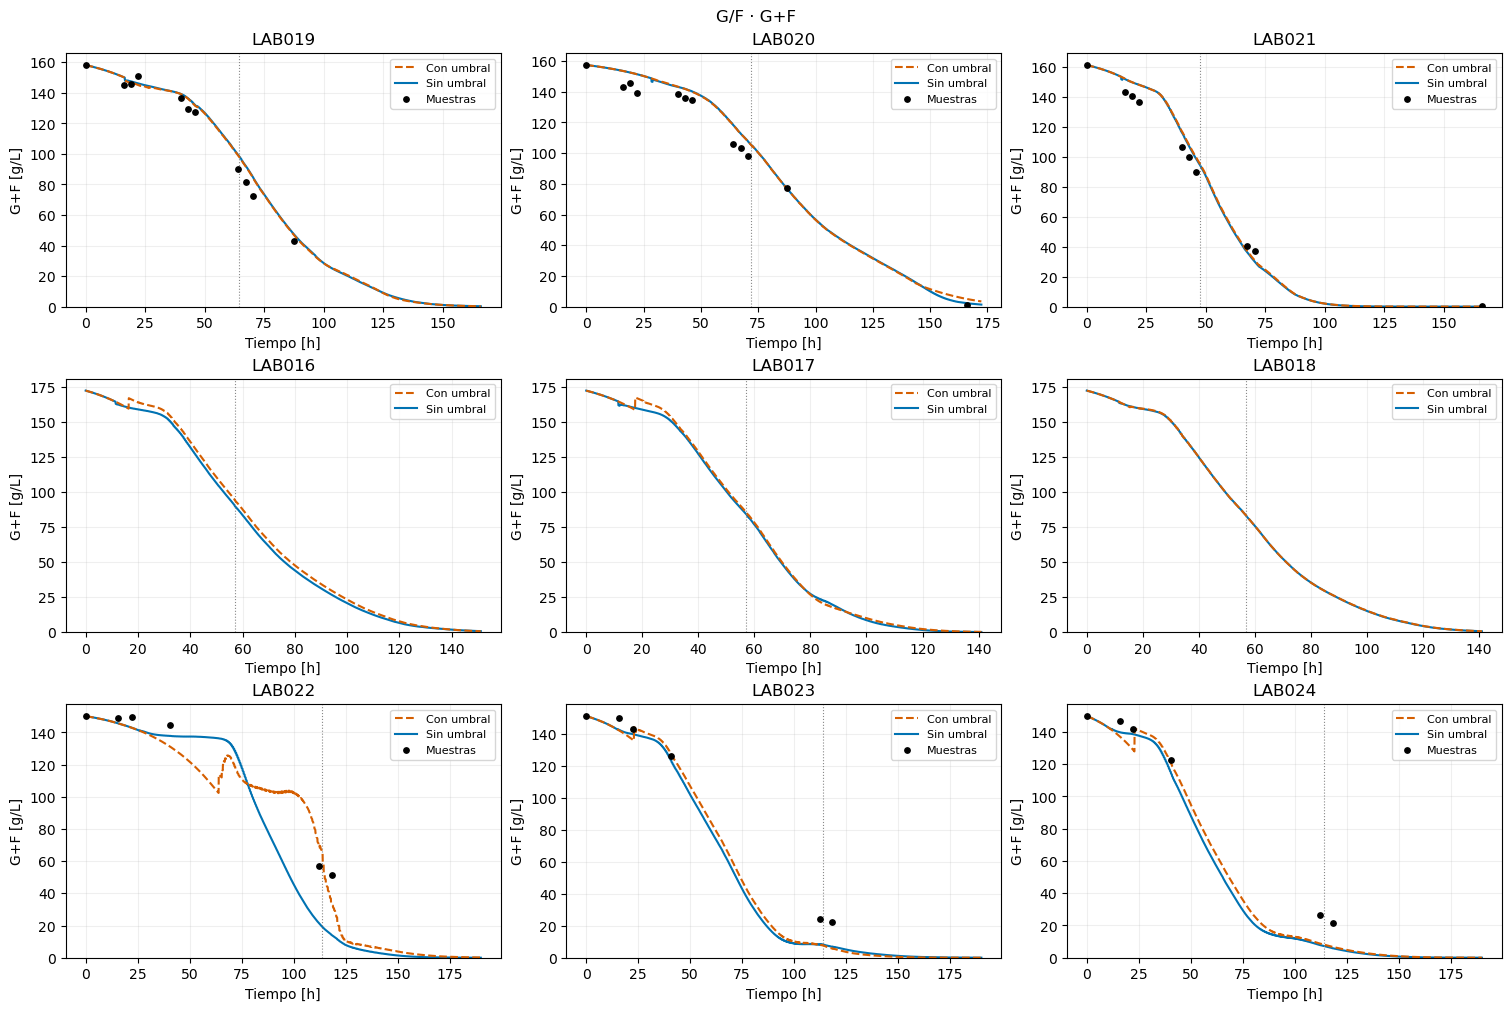

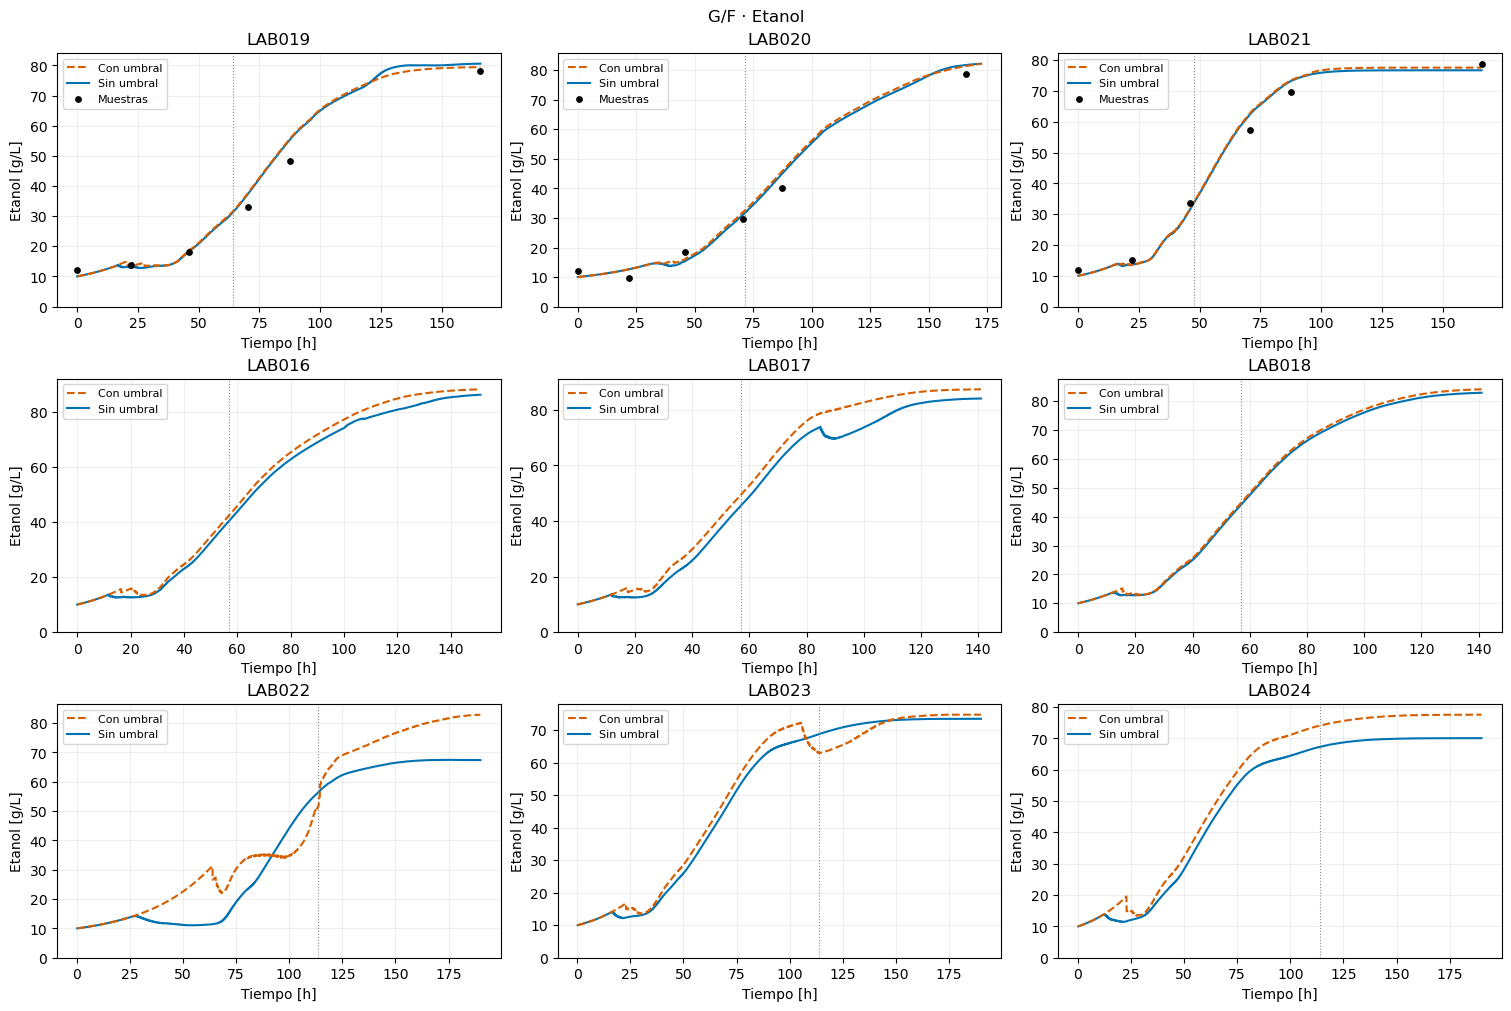

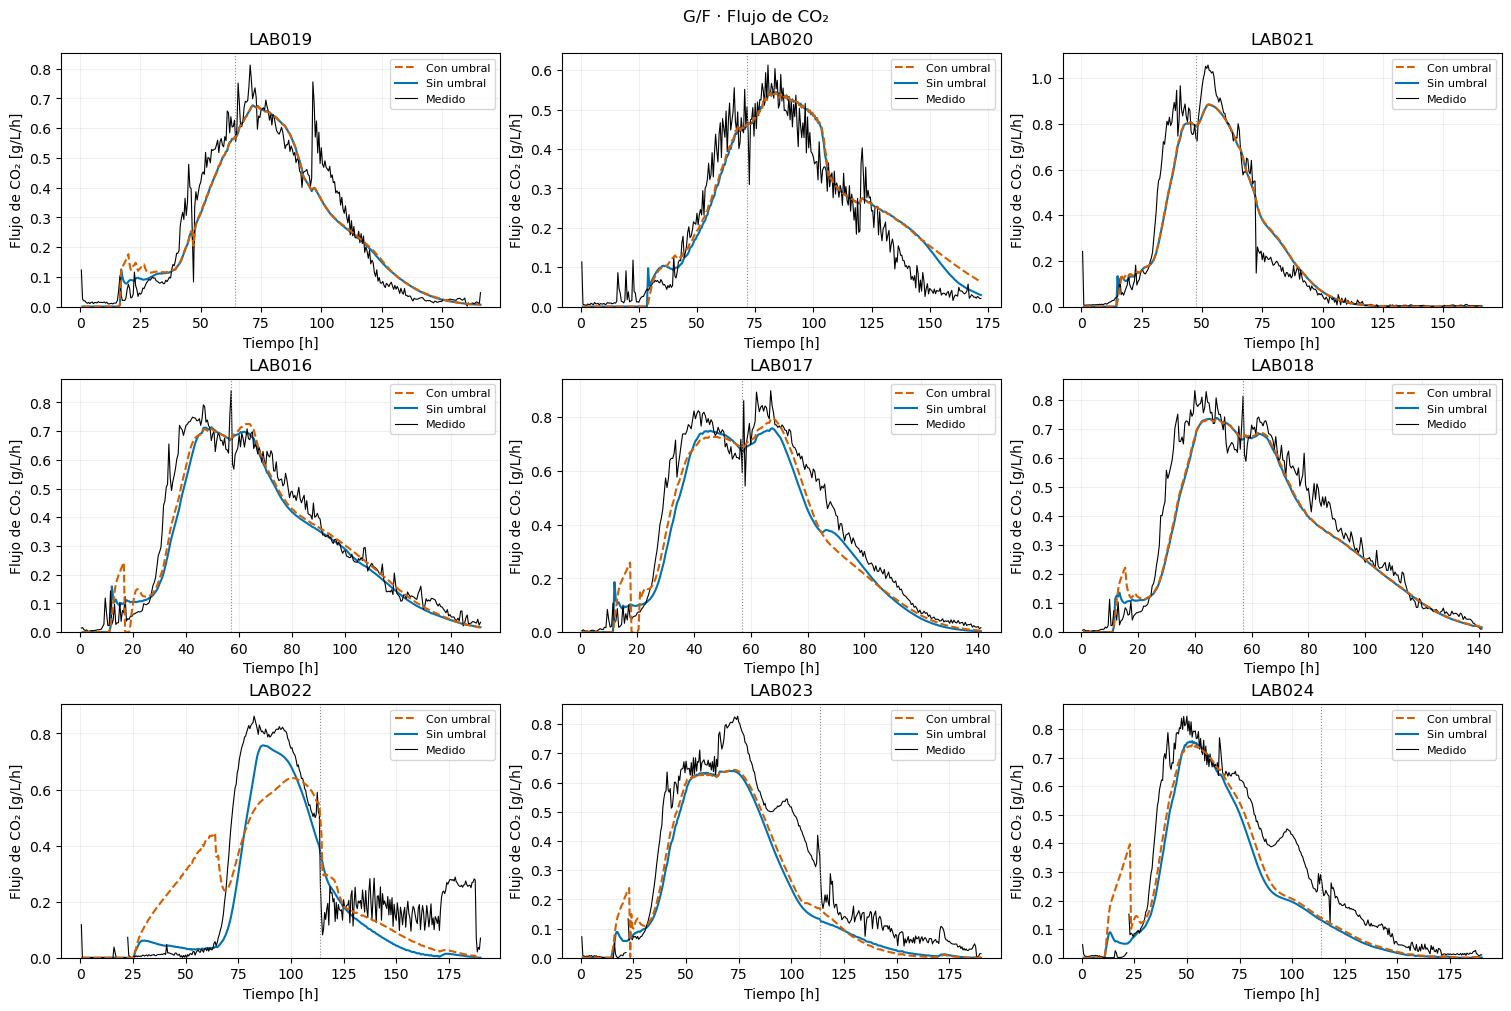

In [6]:
def draw_curves(ax, model, lab, variable, *, legend=True):
    for rule in RULES:
        run = TRAJECTORIES[model, lab, rule]
        if variable == "CO2":
            gas = run["gas"]
            plot = gas.time.ge(1.)
            ax.plot(gas.time[plot], gas.forecast[plot], label=rule, **STYLES[rule])
        else:
            ax.plot(run["time"], run["states"][variable], label=rule, **STYLES[rule])
    if variable == "CO2":
        ax.plot(gas.time, gas.measured.where(gas.valid), c="black", lw=.8, label="Medido")
    else:
        times, values = lab_samples(model, lab, variable)
        if variable == "S":
            density = density_points[lab]
            if len(times) and lab not in ("LAB016","LAB017","LAB018"):
                ax.scatter(times, values, c="black", s=20, zorder=5, label="Muestras Y15")
            ax.scatter(np.r_[density["initial_time"],density["times"]],
                       np.r_[density["initial_sugar"],density["sugar"]],marker="D",facecolors="none",edgecolors="#666666",
                       s=25,zorder=5,label="Densidad convertida")
        elif len(times):
            ax.scatter(times, values, c="black", s=15, zorder=5, label="Muestras")
    for pulse in run["pulse"]:
        ax.axvline(pulse, c="#888888", ls=":", lw=.8)
    title, unit = SYMBOLS[variable]
    lower = min(0., 1.10 * min(density_points[lab]["sugar"])) if variable == "S" else 0.
    ax.set(title=lab, xlabel="Tiempo [h]", ylabel=f"{title} [{unit}]", ylim=(lower, None))
    if lower < 0.:
        ax.axhline(0., c="#888888", lw=.6)
    ax.grid(alpha=.2)
    if legend:
        ax.legend(fontsize=8)


for model, variables in VARIABLES.items():
    for variable in variables:
        fig, axes = plt.subplots(3, 3, figsize=(15, 10), layout="constrained")
        for ax, lab in zip(axes.flat, ORDER):
            draw_curves(ax, model, lab, variable)
        fig.suptitle(f"{model} · {SYMBOLS[variable][0]}")
        plt.show()


## LAB023–024 · ampliaciones del YAN temprano y del flujo de CO₂ tardío

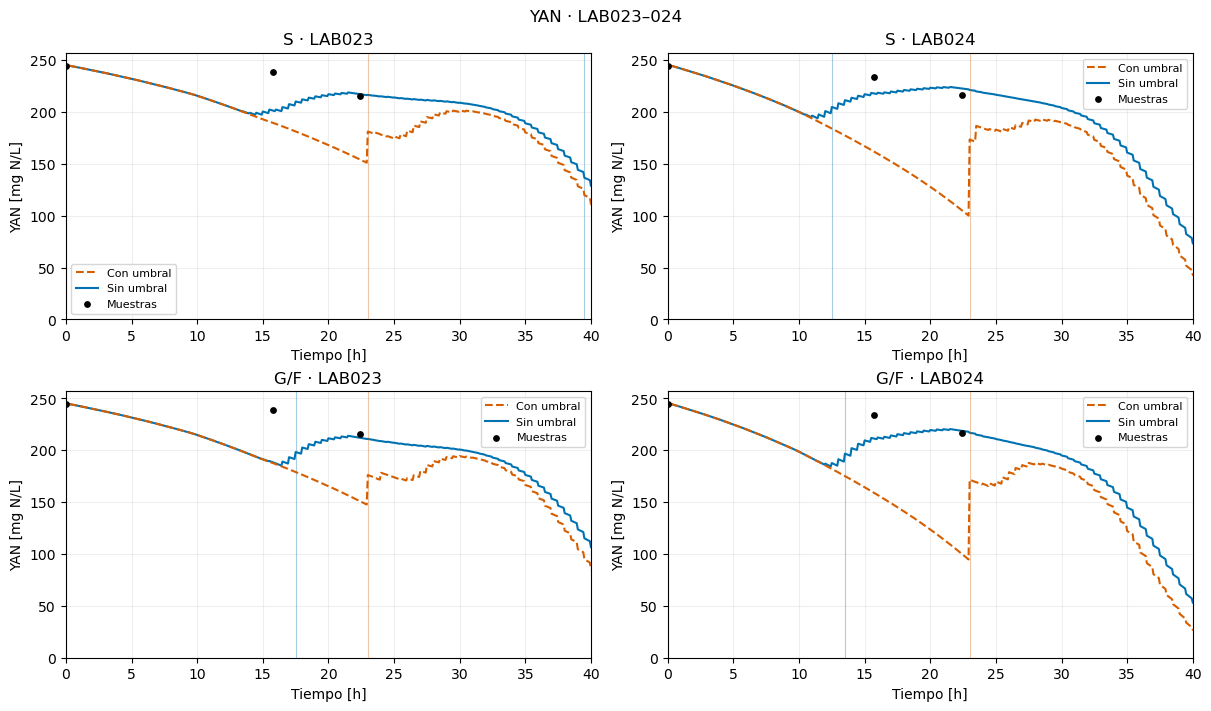

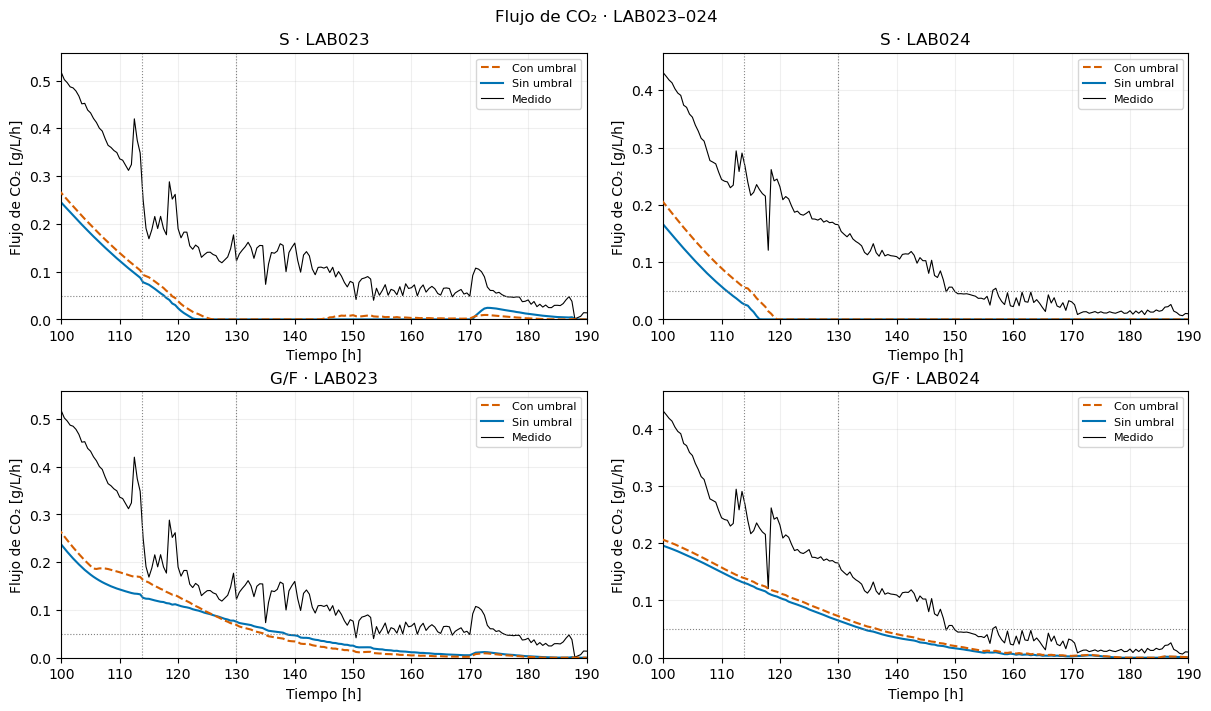

In [7]:
for variable, limits in (("N", (0, 40)), ("CO2", (100, 190))):
    fig, axes = plt.subplots(2, 2, figsize=(12, 7), layout="constrained")
    for row, model in enumerate(VARIABLES):
        for col, lab in enumerate(FOCUS):
            ax = axes[row, col]
            draw_curves(ax, model, lab, variable)
            ax.set(title=f"{model} · {lab}", xlim=limits)
            if variable == "N":
                for rule in RULES:
                    t = metrics.loc[(model, lab, rule), "Hora del mayor salto [h]"]
                    ax.axvline(t, color=STYLES[rule]["c"], alpha=.35, lw=.8)
            else:
                ax.axhline(.05, c="gray", lw=.8, ls=":")
                ax.axvline(130, c="gray", lw=.8, ls=":")
                top = max(max(gas.loc[gas.time.between(*limits), "forecast"])
                          for rule in RULES for gas in [TRAJECTORIES[model, lab, rule]["gas"]])
                observed = TRAJECTORIES[model, lab, WITH_THRESHOLD]["gas"]
                top = max(top, observed.loc[observed.time.between(*limits), "measured"].max())
                ax.set_ylim(0, 1.08 * top)
    fig.suptitle(f"{SYMBOLS[variable][0]} · LAB023–024")
    plt.show()


## Resultado de la prueba con azúcar Y15 y densidad convertida

El modelo S conserva los parámetros de S 17_2 y la configuración de Q del EKF 20. LAB019–024 se inicializan con Y15; LAB016–018 utilizan 156,5 g/L de azúcar inicial, calculados desde densidad con la resta de 16 g/L. Las muestras posteriores se distinguen por origen en los gráficos: puntos para Y15 y rombos vacíos para densidad convertida. Ninguna de esas muestras posteriores se asimila en el filtro.

En LAB020, el azúcar inicial utilizado vuelve a 157,46 g/L (Y15), frente a 171,25 g/L en la prueba anterior con la conversión de densidad sin resta. La nueva conversión de su densidad inicial produce 155,25 g/L y se muestra como referencia. El RMSE de CO₂ desde 130 h disminuye de 0,1915 a 0,1106 g/(L·h) con umbral y de 0,2000 a 0,1135 sin umbral. Se conserva una discrepancia tardía con la medición: cambiar la inicialización mejora esta cola, pero no la explica por completo.


## Diagnóstico de las correcciones cerca del agotamiento de azúcar · LAB023–024

Se repiten las corridas S con las mismas entradas, parámetros y reglas del notebook, registrando la innovación de CO₂ (medición menos pronóstico), las ganancias físicas para azúcar y biomasa, sus correcciones antes y después del recorte de positividad y los estados previos y posteriores. No se asimilan muestras de azúcar ni biomasa. Las ventanas sin actualización conservan correcciones nulas y ganancias no aplicadas ausentes. El signo de la innovación es positivo cuando el CO₂ medido supera al pronosticado.

Las ganancias se expresan en unidades físicas: la corrección propuesta es ganancia por innovación. Se verifica que el registro no cambia estados ni pronósticos del EKF original. Los umbrales de azúcar de 5 y 1 g/L describen la proximidad al agotamiento, no modifican el filtro. Los gráficos se centran en las horas 90–170 y las tablas muestran las primeras correcciones con azúcar previo ≤5 g/L y CO₂ observado mayor que el pronosticado.


In [10]:
diagnostic_source = nbformat.read(next(EKF.glob("20_*.source.ipynb")),4).cells[5].source
diagnostic_source = "def replay_diagnostic(inputs,model):" + diagnostic_source.split("def replay(inputs,model):",1)[1].split("\nmodels =",1)[0]
diagnostic_source=diagnostic_source.replace("    states=[]", "    states=[]\n    diagnostics=[]")
diagnostic_source=diagnostic_source.replace("            prior_yan=", "            prior_state=z.copy()\n            gain_record=np.full(6,np.nan)\n            proposed=np.zeros(6)\n            innovation=measured-predicted\n            prior_yan=")
diagnostic_source=diagnostic_source.replace("                updated=z+gain*innovation", "                gain_record=gain.copy()\n                proposed=gain*innovation\n                updated=z+proposed")
marker="            readings.append("
assert diagnostic_source.count(marker)==1
diagnostic_source=diagnostic_source.replace(marker,'''            diagnostics.append(dict(time=time, valid=valid, update=update,
                measured=measured, forecast=predicted, innovation=innovation,
                gain_S=gain_record[2]*SCALE_EKF[2],gain_X=gain_record[0]*SCALE_EKF[0],
                S_before=prior_state[2]*SCALE_EKF[2],S_after=z[2]*SCALE_EKF[2],
                X_before=prior_state[0]*SCALE_EKF[0],X_after=z[0]*SCALE_EKF[0],
                N_before=prior_state[1]*SCALE_EKF[1]*1000,N_after=z[1]*SCALE_EKF[1]*1000,
                proposed_S=proposed[2]*SCALE_EKF[2],proposed_X=proposed[0]*SCALE_EKF[0],
                delta_S=(z[2]-prior_state[2])*SCALE_EKF[2],delta_X=(z[0]-prior_state[0])*SCALE_EKF[0],
                clipped_S=bool(update and prior_state[2]+proposed[2]<0)))
'''+marker)
diagnostic_source=diagnostic_source.replace("return np.stack(states),readings","return np.stack(states),readings,pd.DataFrame(diagnostics)")
exec(compile(diagnostic_source,"ekf21_innovation_diagnostic","exec"),single)
innovation_logs={};innovation_states={};innovation_rows=[]
for lab in FOCUS:
    inputs=single["data"][lab];sensor=inputs["sensor"]
    for rule in RULES:
        update=sensor["update"] if rule==WITH_THRESHOLD else window_rule(sensor.valid)
        inp={**inputs,"sensor":sensor.assign(update=update)}
        states,readings,log=single["replay_diagnostic"](inp,single_model)
        original_states,original_readings=single["replay"](inp,single_model)
        np.testing.assert_array_equal(states,original_states)
        pd.testing.assert_frame_equal(readings,original_readings)
        active=log.loc[log["update"]]
        np.testing.assert_allclose(active.proposed_S,active.gain_S*active.innovation,atol=1e-12)
        np.testing.assert_allclose(active.delta_S,np.maximum(active.S_before+active.proposed_S,0)-active.S_before,atol=1e-12)
        inactive=log.loc[~log["update"]];assert (inactive.delta_S==0).all() and (inactive.delta_X==0).all()
        innovation_logs[lab,rule]=log;innovation_states[lab,rule]=states
        sugar=states[:,0,2]*single["SCALE_EKF"][2];grid=inputs["grid"]
        after=grid>max(inputs["pulses"])
        hit=np.flatnonzero(after&(sugar<=1))
        t1=grid[hit[0]] if len(hit) else np.nan
        near=active.loc[active.S_before.le(5)&active.time.ge(90)]
        positive=near.loc[near.innovation.gt(0)]
        innovation_rows.append(dict(LAB=lab,Regla=rule,primer_S_le1=t1,
            correcciones_cerca=len(near),innovacion_positiva=len(positive),
            positiva_reduce_S=int((positive.proposed_S<0).sum()),
            positiva_aumenta_S=int((positive.proposed_S>0).sum()),recortes_S=int(near.clipped_S.sum()),
            suma_correccion_S=float(near.delta_S.sum()),suma_correccion_X=float(near.delta_X.sum()),
            max_recuperacion_S=float(near.delta_S.max()) if len(near) else np.nan))
        print(lab,rule,"diagnóstico verificado",flush=True)
innovation_summary=pd.DataFrame(innovation_rows).set_index(["LAB","Regla"])
display(innovation_summary.round(6))
for (lab,rule),log in innovation_logs.items():
    selected=log.loc[log["update"]&log.time.ge(90)&log.S_before.le(5)&log.innovation.gt(0)]
    print(lab,rule,"· primeras correcciones cerca de cero con innovación positiva")
    display(selected[["time","measured","forecast","innovation","gain_S","gain_X","S_before","proposed_S","delta_S","S_after","delta_X","clipped_S"]].head(10).round(7))


LAB023 Con umbral diagnóstico verificado
LAB023 Sin umbral diagnóstico verificado
LAB024 Con umbral diagnóstico verificado
LAB024 Sin umbral diagnóstico verificado
                   primer_S_le1  ...  max_recuperacion_S
LAB    Regla                     ...                    
LAB023 Con umbral    119.916667  ...            0.015498
       Sin umbral    118.666667  ...            0.016707
LAB024 Con umbral    116.000000  ...            0.015651
       Sin umbral    113.916667  ...            0.024963

[4 rows x 9 columns]
LAB023 Con umbral · primeras correcciones cerca de cero con innovación positiva
      time  measured  forecast  ...   S_after   delta_X  clipped_S
220  110.5  0.333207  0.133233  ...  4.911697 -0.006759      False
221  111.0  0.322447  0.128053  ...  4.693126 -0.006551      False
222  111.5  0.311930  0.122751  ...  4.479662 -0.006353      False
223  112.0  0.324243  0.117637  ...  4.272055 -0.006910      False
224  112.5  0.419822  0.112796  ...  4.070618 -0.010214  

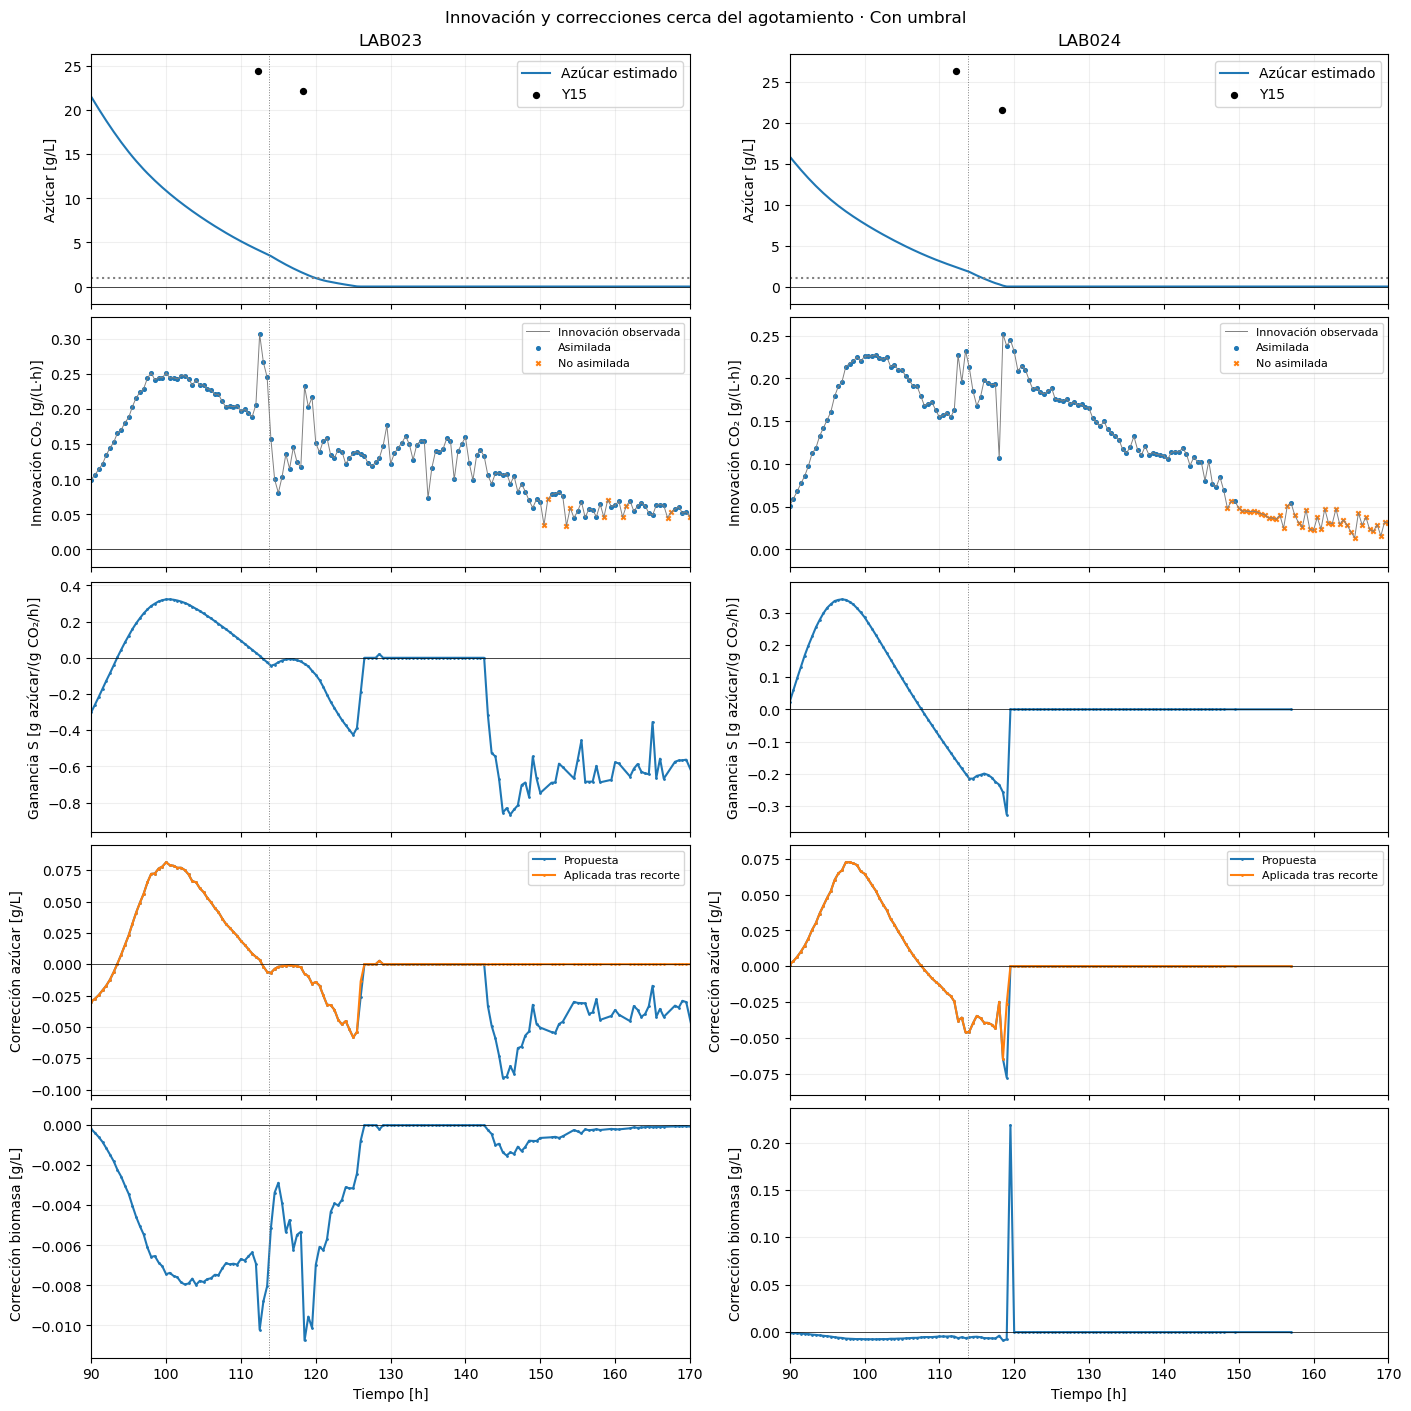

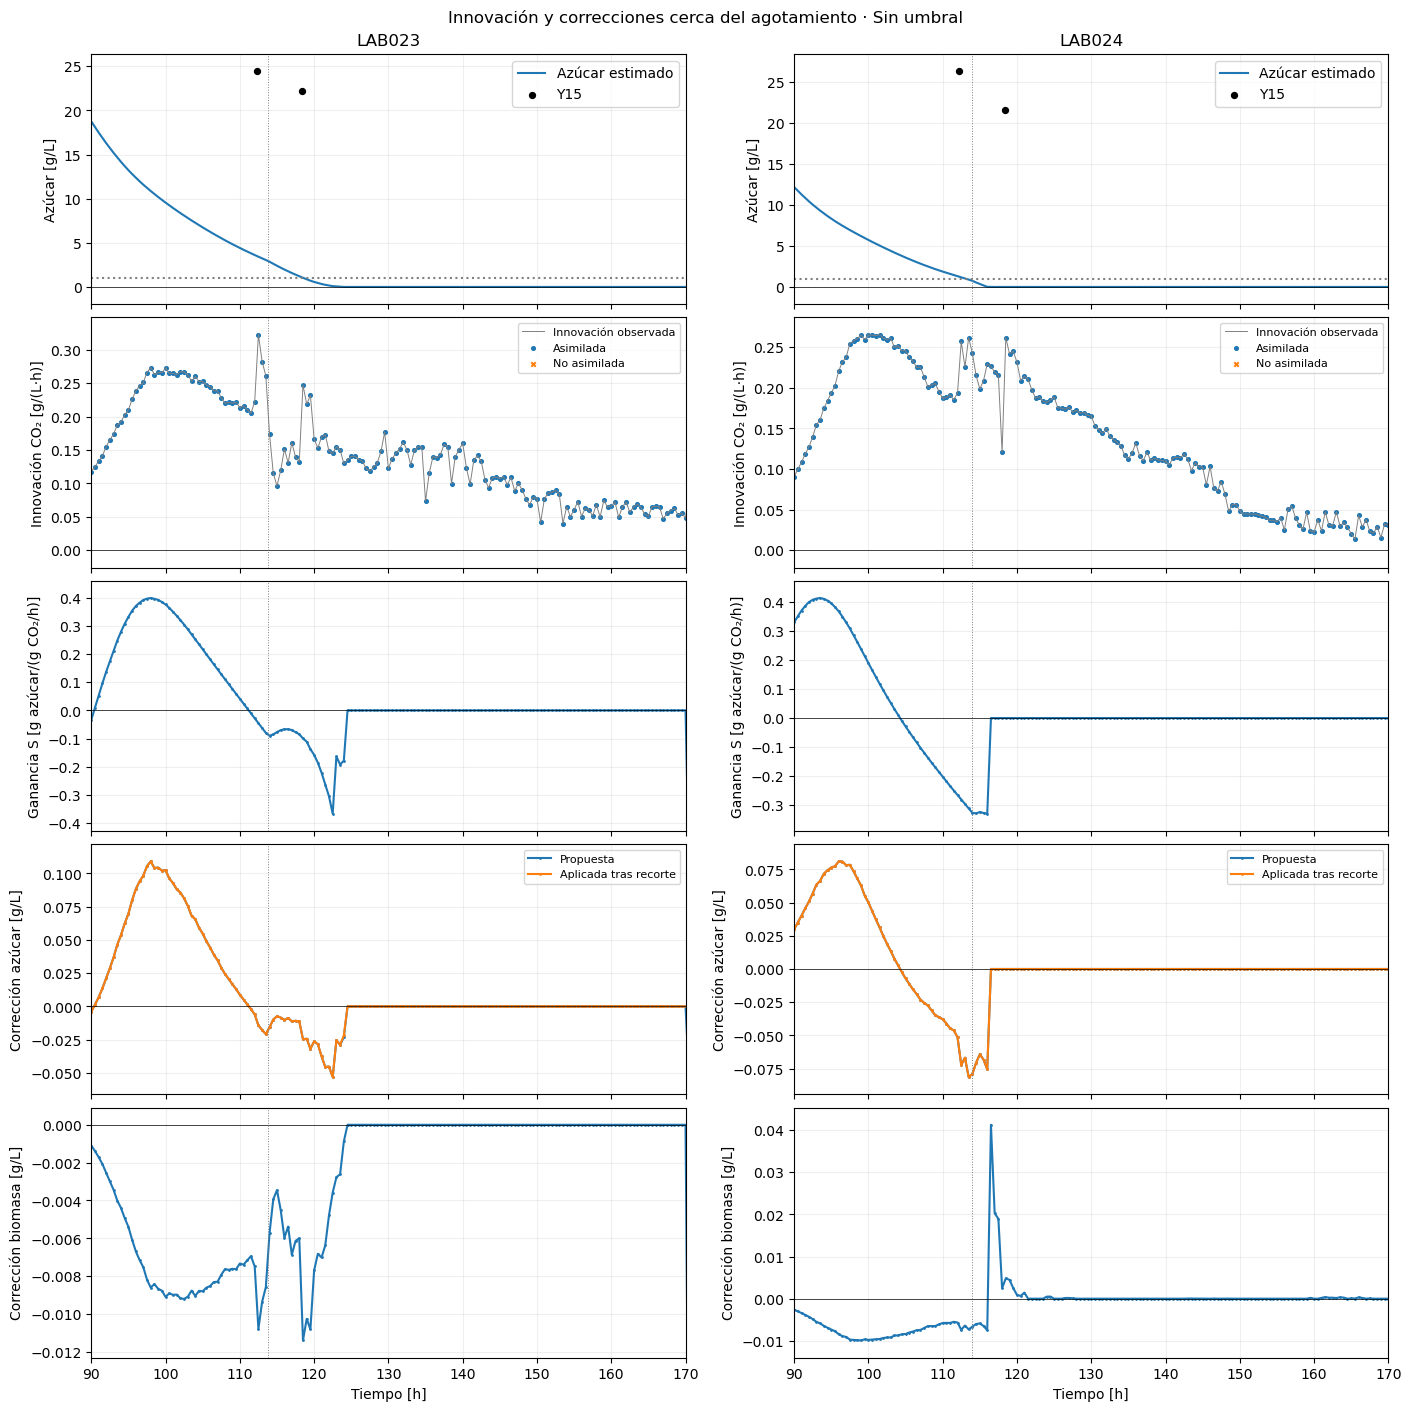

In [12]:
for rule in RULES:
    fig,axes=plt.subplots(5,2,figsize=(14,14),layout="constrained",sharex=True)
    for col,lab in enumerate(FOCUS):
        log=innovation_logs[lab,rule];active=log.loc[log["update"]];inactive=log.loc[log.valid&~log["update"]]
        inputs=single["data"][lab]
        axes[0,col].plot(log.time,log.S_after,label="Azúcar estimado")
        times,values=lab_samples("S",lab,"S")
        axes[0,col].scatter(times,values,c="black",s=18,label="Y15")
        axes[0,col].axhline(1,c="gray",ls=":");axes[0,col].set(title=lab,ylabel="Azúcar [g/L]");axes[0,col].legend()
        axes[1,col].plot(log.time,log.innovation,c="gray",lw=.7,label="Innovación observada")
        axes[1,col].scatter(active.time,active.innovation,s=7,label="Asimilada")
        axes[1,col].scatter(inactive.time,inactive.innovation,marker="x",s=10,label="No asimilada")
        axes[1,col].set_ylabel("Innovación CO₂ [g/(L·h)]");axes[1,col].legend(fontsize=8)
        axes[2,col].plot(active.time,active.gain_S,".-",ms=2);axes[2,col].set_ylabel("Ganancia S [g azúcar/(g CO₂/h)]")
        axes[3,col].plot(active.time,active.proposed_S,".-",ms=2,label="Propuesta")
        axes[3,col].plot(active.time,active.delta_S,".-",ms=2,label="Aplicada tras recorte")
        axes[3,col].set_ylabel("Corrección azúcar [g/L]");axes[3,col].legend(fontsize=8)
        axes[4,col].plot(active.time,active.delta_X,".-",ms=2);axes[4,col].set_ylabel("Corrección biomasa [g/L]")
        for ax in axes[:,col]:
            ax.set_xlim(90,170);ax.axhline(0,c="black",lw=.5);ax.grid(alpha=.2)
            for t in inputs["pulses"]:ax.axvline(t,c="gray",ls=":",lw=.7)
        # Ajustar las escalas solo al tramo visible; evitar que los saltos
        # anteriores a 90 h oculten las correcciones pequeñas de la cola.
        for row,ax in enumerate(axes[:,col]):
            visible=[0.]
            for line in ax.lines:
                if line.get_transform() is not ax.transData:continue
                xx=np.asarray(line.get_xdata(),dtype=float);yy=np.asarray(line.get_ydata(),dtype=float)
                keep=(xx>=90)&(xx<=170)&np.isfinite(yy)
                visible.extend(yy[keep])
            if row==0:
                tt=np.asarray(times);vv=np.asarray(values)
                visible.extend(vv[(tt>=90)&(tt<=170)&np.isfinite(vv)])
            low,high=min(visible),max(visible)
            pad=.08*max(high-low,1e-6)
            ax.set_ylim(low-pad,high+pad)
        axes[4,col].set_xlabel("Tiempo [h]")
    fig.suptitle("Innovación y correcciones cerca del agotamiento · "+rule)
    plt.show()


## Lectura del diagnóstico de innovación

Las corridas instrumentadas reproducen exactamente los estados y los pronósticos originales. La innovación se mantiene positiva durante buena parte de la cola: el sensor indica más CO₂ que el modelo, incluso cuando el azúcar estimado es casi nulo.

La ganancia del azúcar inicialmente permite recuperaciones pequeñas, pero después cambia de signo. En LAB023 sin umbral, a las 119 h, la innovación es +0,2185 g/(L·h), la ganancia física de azúcar es −0,1111 y la corrección reduce S de 0,8930 a 0,8687 g/L. En LAB024 sin umbral, a las 113,5 h, la innovación es +0,2619, la ganancia es −0,3111 y S disminuye de 0,9772 a 0,8957 g/L. En ambos ejemplos la corrección de biomasa también es negativa: −0,0103 y −0,0073 g/L, respectivamente. Por tanto, cerca del agotamiento no se observa simplemente un aumento de biomasa para compensar el CO₂.

Tras alcanzar cero aparecen actualizaciones con ganancia de azúcar nula, aunque la innovación siga siendo positiva. También existen propuestas negativas que se recortan a cero. Quitar el umbral permite seguir incorporando mediciones pequeñas, pero no asegura una ganancia de azúcar positiva ni la recuperación de azúcar residual.

En las actualizaciones desde 90 h con S previo ≤5 g/L, la suma de correcciones aplicadas al azúcar es −0,4884 y −0,5016 g/L en LAB023 (con y sin umbral), y −0,6367 y −0,9653 g/L en LAB024. Estas cifras corresponden a esa ventana: no incluyen las correcciones anteriores ni el consumo por propagación. Las correcciones tardías agravan el agotamiento y no aprovechan adecuadamente la evidencia de CO₂ persistente, pero por sí solas no explican la discrepancia completa, de decenas de g/L, con las muestras de azúcar. La dinámica y la historia previa de estados deben investigarse por separado.

Los gráficos muestran los estados posteriores a las correcciones en los cierres de ventana. Esta sección registra el comportamiento actual; no modifica parámetros, Q, R ni la regla de actualización.


## Corrección directa de azúcar · comparación con CO₂ solamente

Se compara el EKF S con umbral, con y sin asimilación adicional de azúcar, sobre una malla común que incluye las horas exactas de las muestras. LAB019–024 usan Y15 y LAB016–018 densidad convertida. Las muestras iniciales inicializan el estado y no se asimilan otra vez. Las muestras posteriores se incorporan en su horario de muestreo; esta prueba supone disponibilidad inmediata del resultado y no representa el retraso real del laboratorio. Las conversiones negativas de densidad se muestran, pero no se asimilan como concentraciones negativas.

Se utiliza una desviación de 5 g/L para la medición de azúcar (R_S=25 (g/L)²), como supuesto exploratorio común, no como incertidumbre instrumental verificada. La corrección usa la ganancia calculada y la forma de Joseph, con proyección de estados negativos a cero. Si coincide con CO₂, se corrige primero con CO₂ y después con azúcar. Los parámetros químicos, Q y R de CO₂ se conservan. Las muestras incorporadas no son validación independiente; los errores en sus horarios se informan antes de la corrección de azúcar.


En las figuras de azúcar, los cuadrados vacíos magenta identifican las muestras incorporadas por la variante CO₂ + azúcar. La muestra inicial se representa como las demás muestras de su serie y no lleva ese indicador, porque no se vuelve a asimilar. El CO₂ se incorpora solo después de dos ventanas consecutivas válidas de 30 minutos con flujo medido ≥0,05 g/(L·h). Esta regla se aplica tanto a Solo CO₂ como a CO₂ + azúcar; no condiciona la incorporación de las muestras de azúcar.

In [21]:
sugar_sd=5.
sugar_cases={};sugar_measurements={};sugar_scores=[]
source_sugar=nbformat.read(next(EKF.glob("20_*.source.ipynb")),4).cells[5].source
source_sugar="def replay_sugar(inputs,model,assimilate_sugar):"+source_sugar.split("def replay(inputs,model):",1)[1].split("\nmodels =",1)[0]
source_sugar=source_sugar.replace("    states=[]","    states=[]\n    sugar_log=[]")
source_sugar=source_sugar.replace("        states.append(np.stack([z,free]))",'''        if time in inputs['sugar_samples']:
            value=inputs['sugar_samples'][time]
            hs=np.zeros(6);hs[2]=SCALE_EKF[2]
            prior=float(hs@z)
            if assimilate_sugar:
                variance=float(hs@P@hs+sugar_sd**2)
                gain=P@hs/variance
                updated=z+gain*(value-prior)
                z=np.maximum(updated,0.)
                B=IDENTITY-np.outer(gain,hs)
                P=B@P@B.T+np.outer(gain,gain)*sugar_sd**2
                P=(P+P.T)/2
            sugar_log.append((time,value,prior,float(hs@z)))
        states.append(np.stack([z,free]))''')
source_sugar=source_sugar.replace("return np.stack(states),readings","return np.stack(states),readings,pd.DataFrame(sugar_log,columns=['time','measured','prior','posterior'])")
single['sugar_sd']=sugar_sd
exec(compile(source_sugar,'ekf21_direct_sugar','exec'),single)
for lab in ORDER:
    inp=single['data'][lab]
    times,values=lab_samples('S',lab,'S')
    times=np.asarray(times);values=np.asarray(values)
    keep=(times>inp['grid'][0])&(times<=inp['grid'][-1])&np.isfinite(values)&(values>=0)
    samples=dict(zip(np.round(times[keep],10),values[keep]))
    sensor=inp['sensor'].copy()
    validate_base_rule(sensor.valid.to_numpy(),sensor.measured.to_numpy(),sensor['update'].to_numpy())
    run={**inp,'sensor':sensor,'grid':np.unique(np.r_[inp['grid'],list(samples)]),'sugar_samples':samples}
    sugar_measurements[lab]=(times,values)
    for label,enabled in [('Solo CO₂',False),('CO₂ + azúcar',True)]:
        states,gas,records=single['replay_sugar'](run,single_model,enabled)
        sugar_cases[lab,label]=(run,states,gas,records)
        valid=gas.valid&gas.t_h.ge(1.)
        tail=valid&gas.t_h.ge(130.)
        sugar_scores.append(dict(LAB=lab,Caso=label,n=len(records),
            RMSE_azucar_previo=np.sqrt(np.mean((records.prior-records.measured)**2)) if len(records) else np.nan,
            RMSE_CO2=np.sqrt(np.mean((gas.forecast[valid]-gas.measured[valid])**2)),
            RMSE_CO2_cola=np.sqrt(np.mean((gas.forecast[tail]-gas.measured[tail])**2))))
        print(lab,label,'completado',flush=True)
    np.testing.assert_array_equal(sugar_cases[lab,'Solo CO₂'][1][:,1],sugar_cases[lab,'CO₂ + azúcar'][1][:,1])
sugar_scores=pd.DataFrame(sugar_scores).set_index(['LAB','Caso'])
display(sugar_scores.round(5))


LAB019 Solo CO₂ completado
LAB019 CO₂ + azúcar completado
LAB020 Solo CO₂ completado
LAB020 CO₂ + azúcar completado
LAB021 Solo CO₂ completado
LAB021 CO₂ + azúcar completado
LAB016 Solo CO₂ completado
LAB016 CO₂ + azúcar completado
LAB017 Solo CO₂ completado
LAB017 CO₂ + azúcar completado
LAB018 Solo CO₂ completado
LAB018 CO₂ + azúcar completado
LAB022 Solo CO₂ completado
LAB022 CO₂ + azúcar completado
LAB023 Solo CO₂ completado
LAB023 CO₂ + azúcar completado
LAB024 Solo CO₂ completado
LAB024 CO₂ + azúcar completado


n  RMSE_azucar_previo  RMSE_CO2  RMSE_CO2_cola
LAB    Caso                                                         
LAB019 Solo CO₂      11             7.57833   0.06253        0.01433
       CO₂ + azúcar  11             7.68721   0.06218        0.01462
LAB020 Solo CO₂      11             8.79404   0.07938        0.11057
       CO₂ + azúcar  11             4.87733   0.05886        0.03526
LAB021 Solo CO₂       9             9.22815   0.11236        0.00433
       CO₂ + azúcar   9             9.96571   0.10647        0.00435
LAB016 Solo CO₂       8             8.49354   0.11763        0.07138
       CO₂ + azúcar   8             8.11357   0.11597        0.07156
LAB017 Solo CO₂       8             5.05561   0.14536        0.03025
       CO₂ + azúcar   8             3.59989   0.14556        0.03023
LAB018 Solo CO₂       8             6.62180   0.11089        0.04704
       CO₂ + azúcar   8             4.87033   0.11205        0.04689
LAB022 Solo CO₂       5            13.23715   0.19865        0.16568
       CO₂ + azúcar   5            18.54179   0.17254        0.18624
LAB023 Solo CO₂       5            14.15099   0.13399        0.08414
       CO₂ + azúcar   5            13.74339   0.13167        0.08347
LAB024 Solo CO₂       5            16.62065   0.13629        0.06915
       CO₂ + azúcar   5            15.68830   0.13086        0.06915

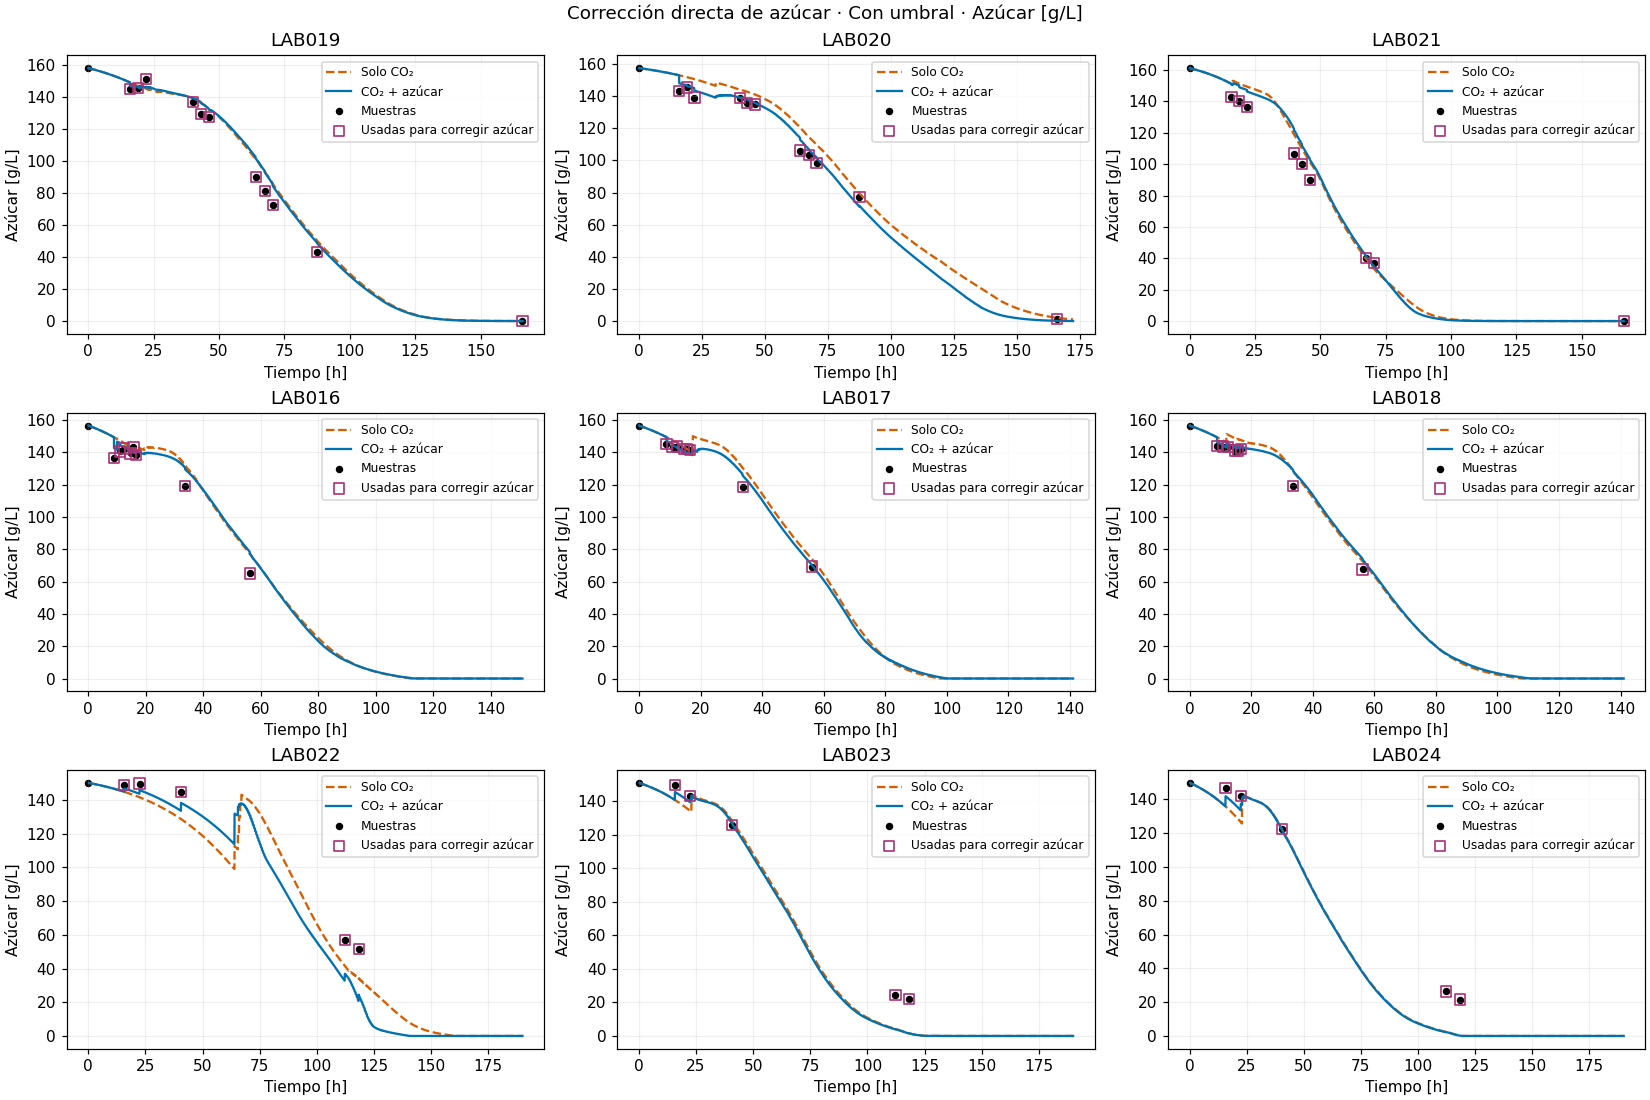

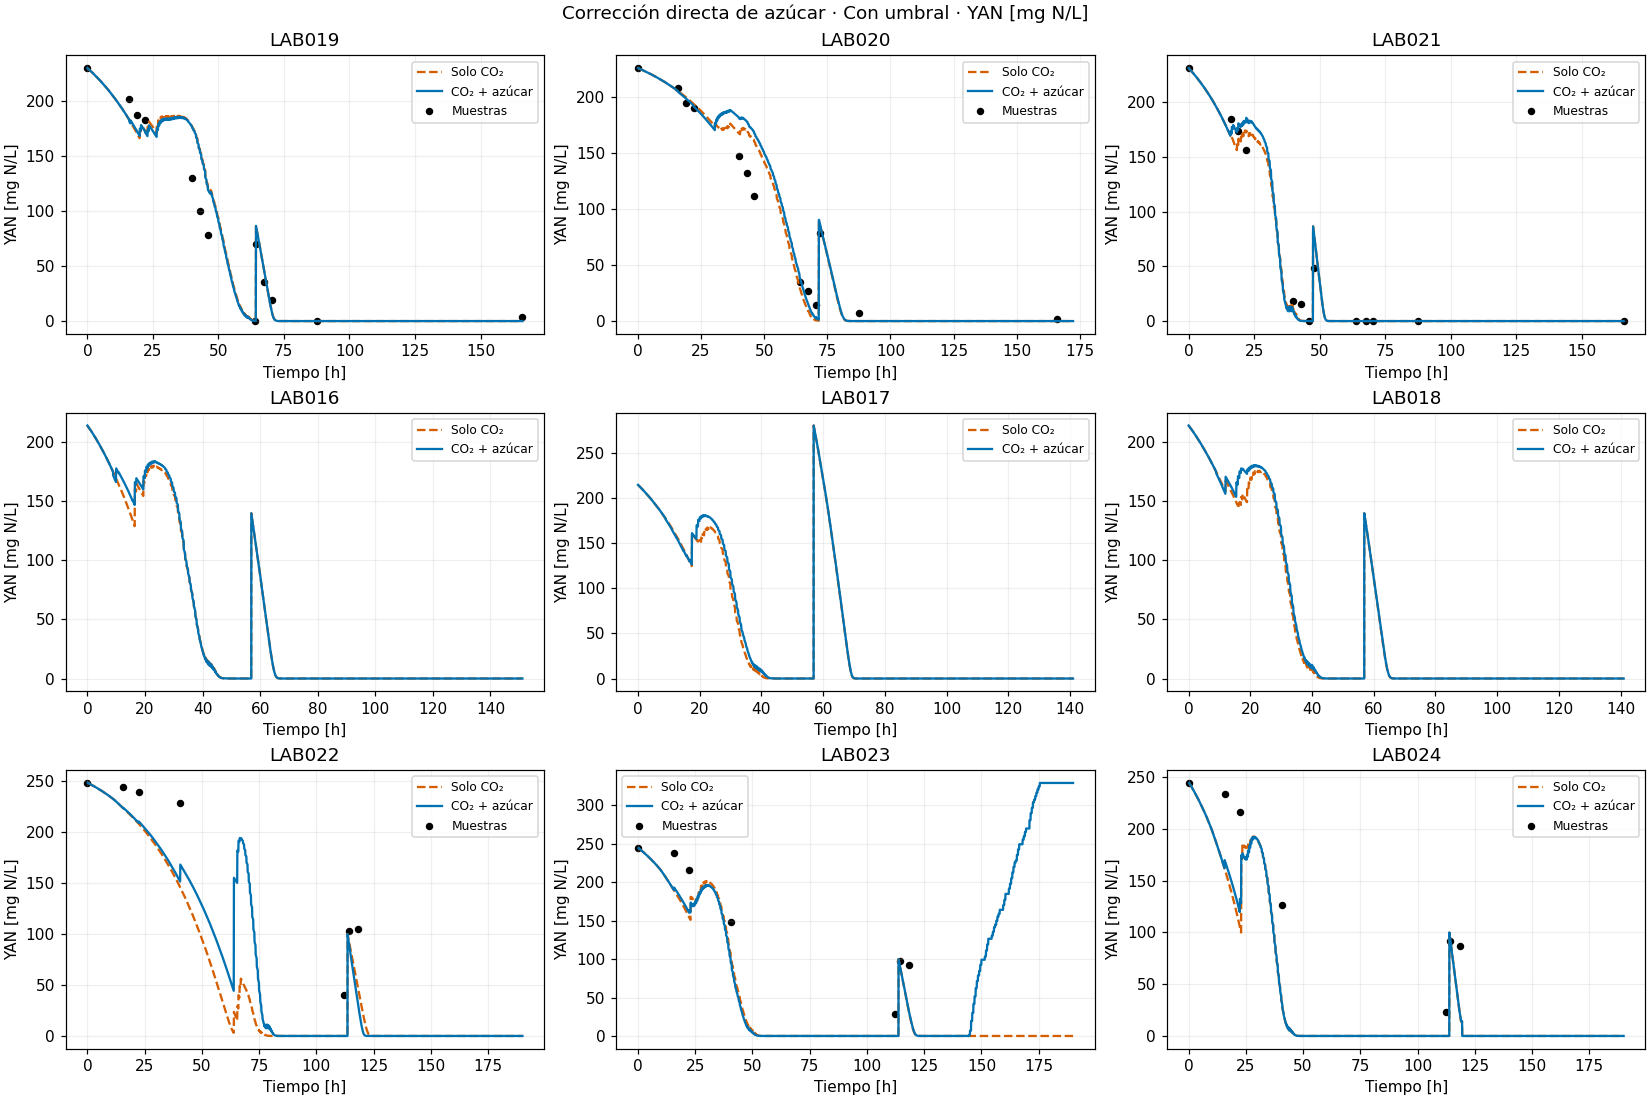

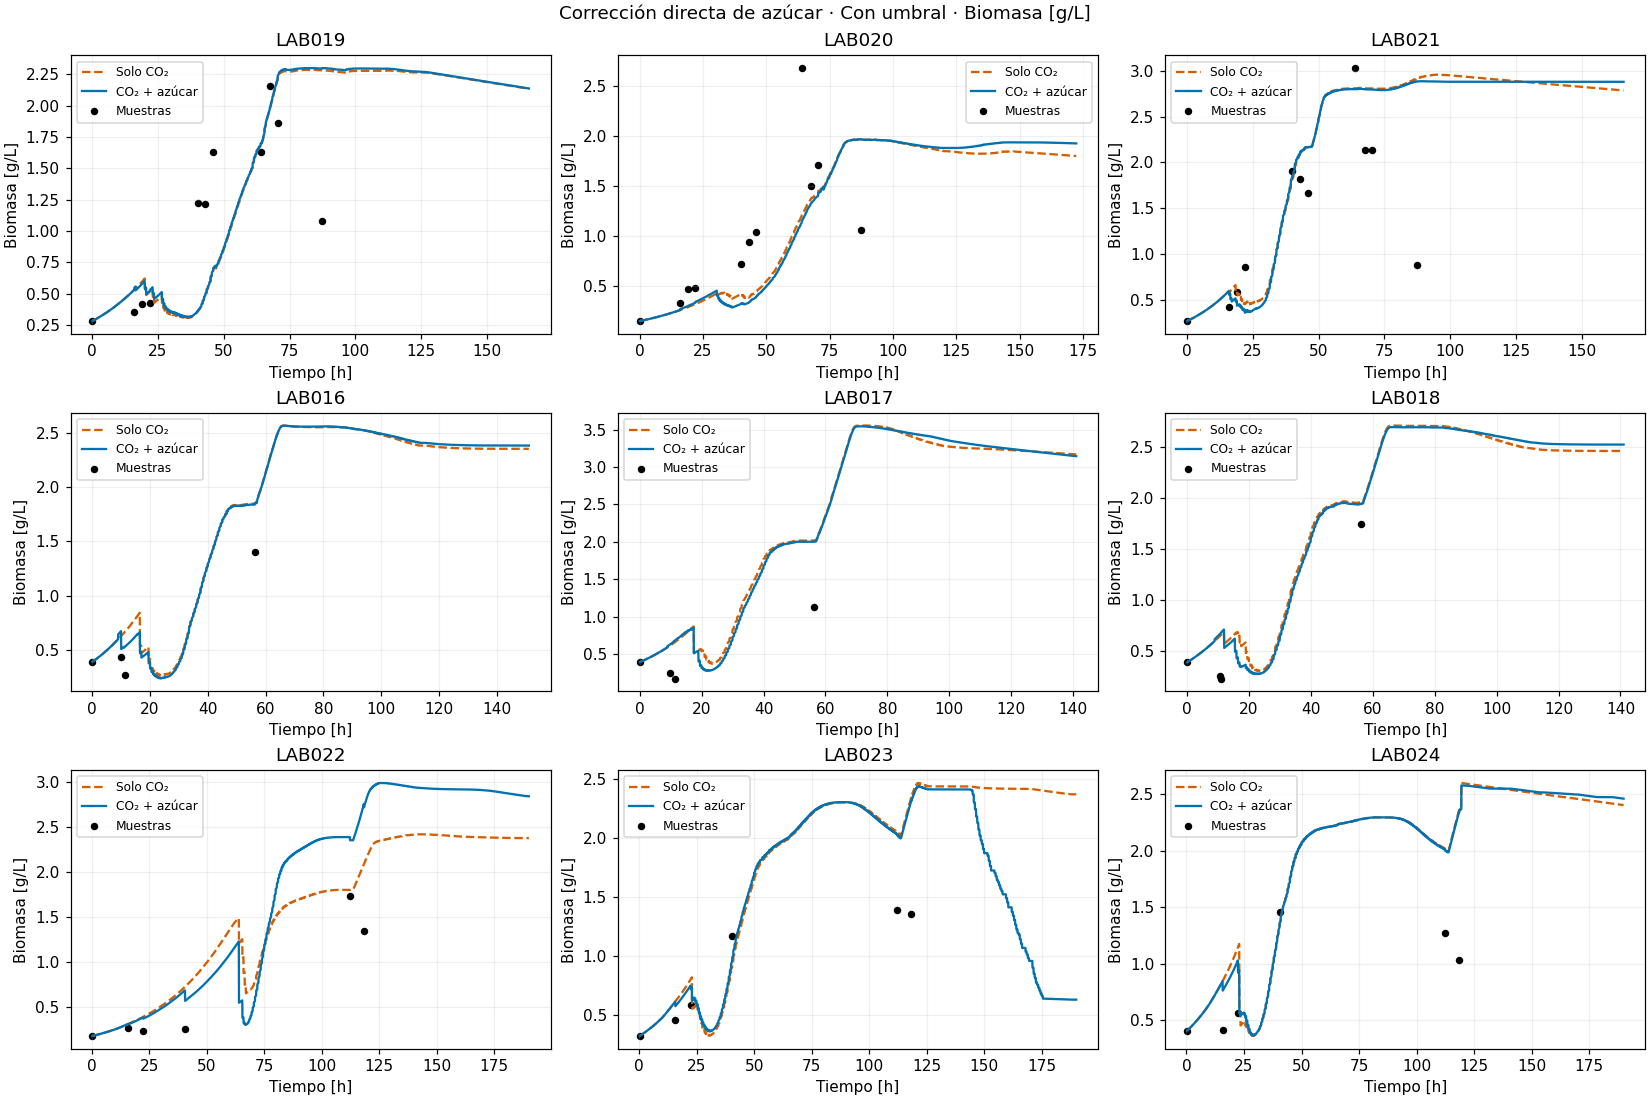

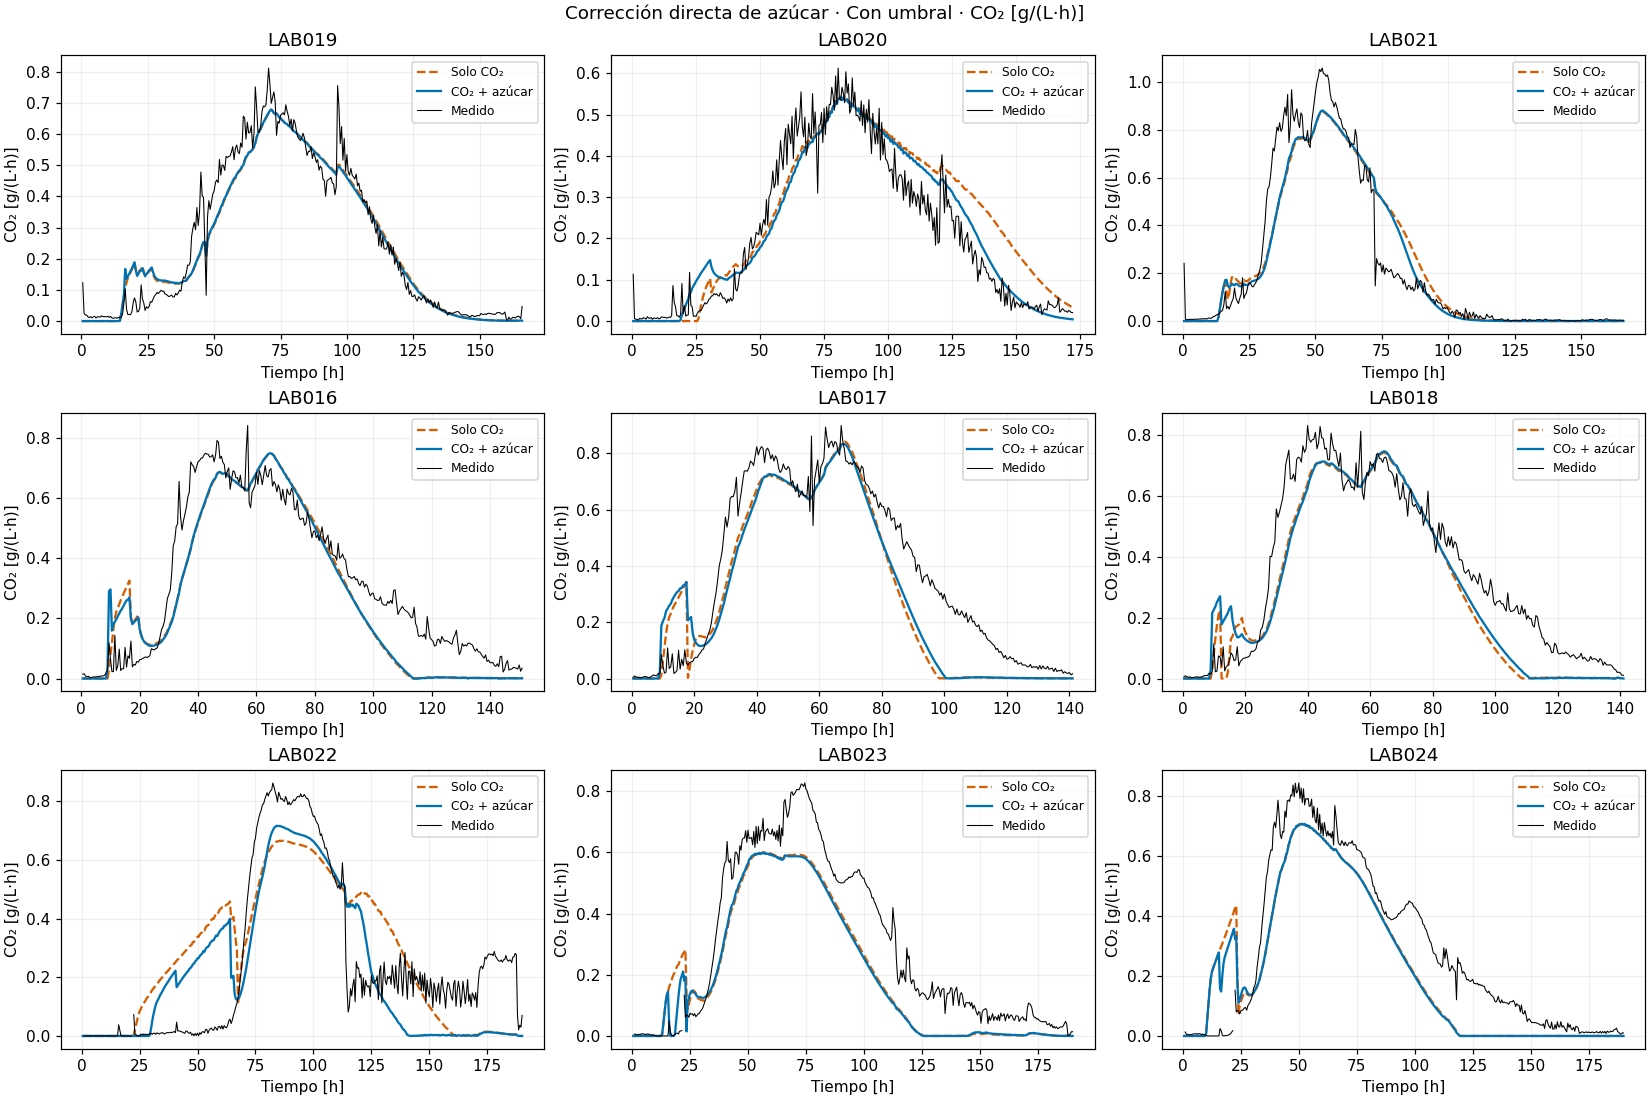

In [22]:
for variable,index,scale,ylabel in [('S',2,1.,'Azúcar [g/L]'),('N',1,1000.,'YAN [mg N/L]'),('X',0,1.,'Biomasa [g/L]'),('CO2',None,1.,'CO₂ [g/(L·h)]')]:
    fig,axes=plt.subplots(3,3,figsize=(15,10),layout='constrained')
    for ax,lab in zip(axes.flat,ORDER):
        for label,color,style in [('Solo CO₂','#D55E00','--'),('CO₂ + azúcar','#0072B2','-')]:
            run,states,gas,records=sugar_cases[lab,label]
            ax.plot(gas.t_h if variable=='CO2' else run['grid'],gas.forecast if variable=='CO2' else states[:,0,index]*single['SCALE_EKF'][index]*scale,c=color,ls=style,label=label)
        if variable=='CO2':ax.plot(gas.t_h,gas.measured.where(gas.valid),c='black',lw=.7,label='Medido')
        else:
            tt,vv=lab_samples('S',lab,variable)
            if variable=='S' and lab in ('LAB016','LAB017','LAB018'):
                d=density_points[lab];tt=np.r_[d['initial_time'],d['times']];vv=np.r_[d['initial_sugar'],d['sugar']]
            if len(tt):ax.scatter(tt,vv,c='black',s=15,label='Muestras')
            if variable=='S' and len(records):
                ax.scatter(records.time,records.measured,marker='s',facecolors='none',edgecolors='#AA3377',s=45,linewidths=1.1,zorder=6,label='Usadas para corregir azúcar')
        ax.set(title=lab,xlabel='Tiempo [h]',ylabel=ylabel);ax.grid(alpha=.2);ax.legend(fontsize=8)
    fig.suptitle('Corrección directa de azúcar · Con umbral · '+ylabel)
    plt.show()


In [23]:
sugar_update_details=[]
for lab in ("LAB020","LAB023","LAB024"):
    for label in ("Solo CO₂","CO₂ + azúcar"):
        records=sugar_cases[lab,label][3].tail(2).copy()
        records["LAB"]=lab;records["Caso"]=label
        records["Corrección S [g/L]"]=records.posterior-records.prior
        records["Ganancia directa efectiva"]=records["Corrección S [g/L]"]/(records.measured-records.prior)
        sugar_update_details.append(records)
sugar_update_details=pd.concat(sugar_update_details,ignore_index=True)
display(sugar_update_details.round(6))


,time,measured,prior,posterior,LAB,Caso,Corrección S [g/L],Ganancia directa efectiva
0,87.500000,77.25,79.560532,79.560532,LAB020,Solo CO₂,0.000000,-0.000000
1,166.000000,1.35,2.143165,2.143165,LAB020,Solo CO₂,0.000000,-0.000000
2,87.500000,77.25,71.243699,71.860560,LAB020,CO₂ + azúcar,0.616861,0.102702
3,166.000000,1.35,0.281485,0.284053,LAB020,CO₂ + azúcar,0.002568,0.002404
4,112.250000,24.43,4.168584,4.168584,LAB023,Solo CO₂,0.000000,0.000000
5,118.333333,22.18,1.525633,1.525633,LAB023,Solo CO₂,0.000000,0.000000
6,112.250000,24.43,3.922969,4.071931,LAB023,CO₂ + azúcar,0.148962,0.007264
7,118.333333,22.18,1.440320,1.533019,LAB023,CO₂ + azúcar,0.092699,0.004470
8,112.250000,26.34,2.384265,2.384265,LAB024,Solo CO₂,0.000000,0.000000
9,118.333333,21.57,0.202299,0.202299,LAB024,Solo CO₂,0.000000,0.000000


## Resultado de la corrección directa · CO₂ con umbral

Las dos variantes usan la misma regla de CO₂: dos ventanas consecutivas válidas de 30 minutos con flujo medido ≥0,05 g/(L·h). La diferencia entre ellas es incorporar o no las muestras posteriores de azúcar. El umbral no bloquea las mediciones de azúcar. Las muestras iniciales se muestran igual que las demás de su serie; los cuadrados magenta señalan exclusivamente muestras posteriores usadas para corregir.

En LAB020, el error cuadrático medio de azúcar antes de incorporar cada muestra pasa de 8.794 a 4.877 g/L; el del pronóstico de CO₂ en la cola desde 130 h pasa de 0.11057 a 0.03526 g/(L·h).

En LAB023, el error cuadrático medio de azúcar antes de incorporar cada muestra pasa de 14.151 a 13.743 g/L; el del pronóstico de CO₂ en la cola desde 130 h pasa de 0.08414 a 0.08347 g/(L·h).

En LAB024, el error cuadrático medio de azúcar antes de incorporar cada muestra pasa de 16.621 a 15.688 g/L; el del pronóstico de CO₂ en la cola desde 130 h pasa de 0.06915 a 0.06915 g/(L·h).

Los errores en las horas de muestreo se calculan antes de corregir con azúcar; aun así, las muestras utilizadas forman parte de la estimación y no constituyen validación independiente. Se conserva el supuesto exploratorio de 5 g/L, que debe justificarse con la precisión y preparación de las muestras, y se supone disponibilidad inmediata del resultado. No se recalibran la química ni la capa de CO₂, ni se modifica Q.


## Covarianza del azúcar y sensibilidad a su incertidumbre de medición

Para LAB023–024 se repite la variante con umbral con corrección directa de Y15, sin cambiar parámetros químicos ni Q ni R de CO₂. Se conserva la regla de dos ventanas consecutivas válidas de 30 minutos con flujo medido ≥0,05 g/(L·h), también al recorrer la incertidumbre de azúcar. Se registra P_SS en unidades físicas (g/L)² al inicio del paso, tras la propagación, después del CO₂ y después de la medición de azúcar. También se registran la contribución de Q y la sensibilidad numérica J_SS de la transición. La incertidumbre de medición se recorre en 1, 2,5, 5 y 10 g/L como prueba exploratoria, sin seleccionar un valor solo por ajuste.

Para una medición directa de azúcar, la ganancia física es K_SS=P_SS/(P_SS+σ_S²). La incertidumbre de 5 g/L significa R_S=25 (g/L)². Se contrastan ganancias calculadas desde P con las correcciones efectivamente aplicadas. El error en el horario de las muestras se calcula antes de incorporar la medición. Los datos asimilados no constituyen validación independiente.


In [26]:
cov_source=source_sugar.replace('def replay_sugar(inputs,model,assimilate_sugar):','def replay_covariance(inputs,model,assimilate_sugar,sigma_s):')
cov_source=cov_source.replace('sugar_sd**2','sigma_s**2')
cov_source=cov_source.replace('    sugar_log=[]','    sugar_log=[]\n    covariance_log=[]\n    direct_log=[]')
cov_source=cov_source.replace('    for i,time in enumerate(grid):','''    for i,time in enumerate(grid):
        variance_start=float(P[2,2]*SCALE_EKF[2]**2)
        variance_deterministic=variance_start
        q_s=0.;j_s=1.
''')
cov_source=cov_source.replace('            P=J@P@J.T+process','''            variance_deterministic=float((J@P@J.T)[2,2]*SCALE_EKF[2]**2)
            q_s=float(process[2,2]*SCALE_EKF[2]**2);j_s=float(J[2,2])
            P=J@P@J.T+process''')
cov_source=cov_source.replace('        if time in windows:','''        variance_propagated=float(P[2,2]*SCALE_EKF[2]**2)
        if time in windows:''')
cov_source=cov_source.replace("        if time in inputs['sugar_samples']:",'''        variance_co2=float(P[2,2]*SCALE_EKF[2]**2)
        if time in inputs['sugar_samples']:''')
cov_source=cov_source.replace('            sugar_log.append((time,value,prior,float(hs@z)))','''            direct_log.append(dict(time=time,measured=value,prior=prior,posterior=float(hs@z),
                variance_prior=variance_co2,variance_posterior=float(P[2,2]*SCALE_EKF[2]**2),
                sd_prior=np.sqrt(max(variance_co2,0)),R_s=sigma_s**2,
                gain_direct=variance_co2/(variance_co2+sigma_s**2),
                correction=float(hs@z)-prior,N_after=float(z[1]*SCALE_EKF[1]*1000)))
            sugar_log.append((time,value,prior,float(hs@z)))''')
cov_source=cov_source.replace('        states.append(np.stack([z,free]))','''        covariance_log.append(dict(time=time,S=float(z[2]*SCALE_EKF[2]),N=float(z[1]*SCALE_EKF[1]*1000),
            variance_start=variance_start,variance_deterministic=variance_deterministic,
            q_s=q_s,j_s=j_s,variance_propagated=variance_propagated,
            variance_after_co2=variance_co2,variance_final=float(P[2,2]*SCALE_EKF[2]**2)))
        states.append(np.stack([z,free]))''')
cov_source=cov_source.replace("pd.DataFrame(sugar_log,columns=['time','measured','prior','posterior'])","pd.DataFrame(sugar_log,columns=['time','measured','prior','posterior']),pd.DataFrame(covariance_log),pd.DataFrame(direct_log)")
exec(compile(cov_source,'ekf21_covariance_diagnostic','exec'),single)
covariance_runs={};covariance_rows=[]
for lab in ('LAB023','LAB024'):
    inp=single['data'][lab]
    times,values=lab_samples('S',lab,'S');times=np.asarray(times);values=np.asarray(values)
    keep=(times>inp['grid'][0])&(times<=inp['grid'][-1])&np.isfinite(values)&(values>=0)
    samples=dict(zip(np.round(times[keep],10),values[keep]))
    run={**inp,'sensor':inp['sensor'].copy(),
         'grid':np.unique(np.r_[inp['grid'],list(samples)]),'sugar_samples':samples}
    validate_base_rule(run['sensor'].valid.to_numpy(),run['sensor'].measured.to_numpy(),run['sensor']['update'].to_numpy())
    for sigma in (1.,2.5,5.,10.):
        states,gas,records,trace,direct=single['replay_covariance'](run,single_model,True,sigma)
        covariance_runs[lab,sigma]=(states,gas,trace,direct)
        assert np.isfinite(trace.to_numpy()).all() and trace.variance_final.min()>=-1e-10
        np.testing.assert_allclose(direct.correction,direct.gain_direct*(direct.measured-direct.prior),atol=1e-9)
        if sigma==5.:
            single['sugar_sd']=5.
            ref_states,ref_gas,ref_records=single['replay_sugar'](run,single_model,True)
            np.testing.assert_array_equal(states,ref_states);pd.testing.assert_frame_equal(gas,ref_gas)
        tail=gas.valid&gas.t_h.ge(130.)
        last=direct.iloc[-1]
        covariance_rows.append(dict(LAB=lab,sigma_s=sigma,RMSE_S_previo=np.sqrt(np.mean((direct.prior-direct.measured)**2)),
            RMSE_CO2_cola=np.sqrt(np.mean((gas.forecast[tail]-gas.measured[tail])**2)),
            ultima_hora=last.time,S_previo=last.prior,S_medido=last.measured,S_posterior=last.posterior,
            P_SS_previo=last.variance_prior,sigma_estado_previo=last.sd_prior,ganancia=last.gain_direct))
        print(lab,'sigma azúcar',sigma,'completado',flush=True)
covariance_summary=pd.DataFrame(covariance_rows).set_index(['LAB','sigma_s'])
display(covariance_summary.round(8))
for lab in ('LAB023','LAB024'):
    print(lab,'· registro de todas las mediciones de azúcar con σ=5 g/L')
    display(covariance_runs[lab,5.][3].round(9))
    direct=covariance_runs[lab,5.][3]
    last=direct.iloc[-1];v=last.variance_prior
    display(pd.DataFrame({'σ medición [g/L]':[1.,2.5,5.,10.],
        'Ganancia con P previo idéntico':[v/(v+s*s) for s in (1.,2.5,5.,10.)]}))


LAB023 sigma azúcar 1.0 completado
LAB023 sigma azúcar 2.5 completado
LAB023 sigma azúcar 5.0 completado
LAB023 sigma azúcar 10.0 completado
LAB024 sigma azúcar 1.0 completado
LAB024 sigma azúcar 2.5 completado
LAB024 sigma azúcar 5.0 completado
LAB024 sigma azúcar 10.0 completado
LAB023 · registro de todas las mediciones de azúcar con σ=5 g/L
LAB024 · registro de todas las mediciones de azúcar con σ=5 g/L


RMSE_S_previo  RMSE_CO2_cola  ...  sigma_estado_previo  ganancia
LAB    sigma_s                                ...                               
LAB023 1.0          13.305817       0.083277  ...             0.345731  0.106768
       2.5          13.654510       0.083648  ...             0.334135  0.017550
       5.0          13.743386       0.083472  ...             0.335026  0.004470
       10.0         13.898388       0.083902  ...             0.341049  0.001162
LAB024 1.0          15.248705       0.068012  ...             0.279922  0.072663
       2.5          15.909661       0.069146  ...             0.032660  0.000171
       5.0          15.688297       0.069146  ...             0.268541  0.002876
       10.0         16.492946       0.069146  ...             0.032660  0.000011

[8 rows x 9 columns]

,time,measured,prior,posterior,variance_prior,variance_posterior,sd_prior,R_s,gain_direct,correction,N_after
0,15.750000,149.63,140.783122,145.522469,28.845479,13.392712,5.370799,25.0,0.535708,4.739348,193.185820
1,22.416667,143.22,139.395555,140.950667,17.131823,10.165608,4.139061,25.0,0.406624,1.555112,163.408417
2,40.583333,126.06,126.974887,126.966002,0.245175,0.242794,0.495151,25.0,0.009712,-0.008885,95.052199
3,112.250000,24.43,3.922969,4.071931,0.182927,0.181598,0.427700,25.0,0.007264,0.148962,0.000000
4,118.333333,22.18,1.440320,1.533019,0.112243,0.111741,0.335026,25.0,0.004470,0.092699,31.986927


,σ medición [g/L],Ganancia con P previo idéntico
0,1.0,0.100916
1,2.5,0.017642
2,5.0,0.004470
3,10.0,0.001121


,time,measured,prior,posterior,variance_prior,variance_posterior,sd_prior,R_s,gain_direct,correction,N_after
0,15.750000,146.67,135.856925,141.927549,32.001506,14.035378,5.656987,25.0,0.561415,6.070623,169.971476
1,22.416667,141.84,133.482029,137.273833,20.760320,11.341879,4.556349,25.0,0.453675,3.791804,132.505488
2,40.583333,122.63,121.548592,121.557511,0.207895,0.206180,0.455955,25.0,0.008247,0.008919,33.635026
3,112.250000,26.34,2.199047,2.317702,0.123484,0.122877,0.351403,25.0,0.004915,0.118655,0.000000
4,118.333333,21.57,0.125188,0.186869,0.072115,0.071907,0.268541,25.0,0.002876,0.061681,23.645883


,σ medición [g/L],Ganancia con P previo idéntico
0,1.0,0.067264
1,2.5,0.011407
2,5.0,0.002876
3,10.0,0.000721


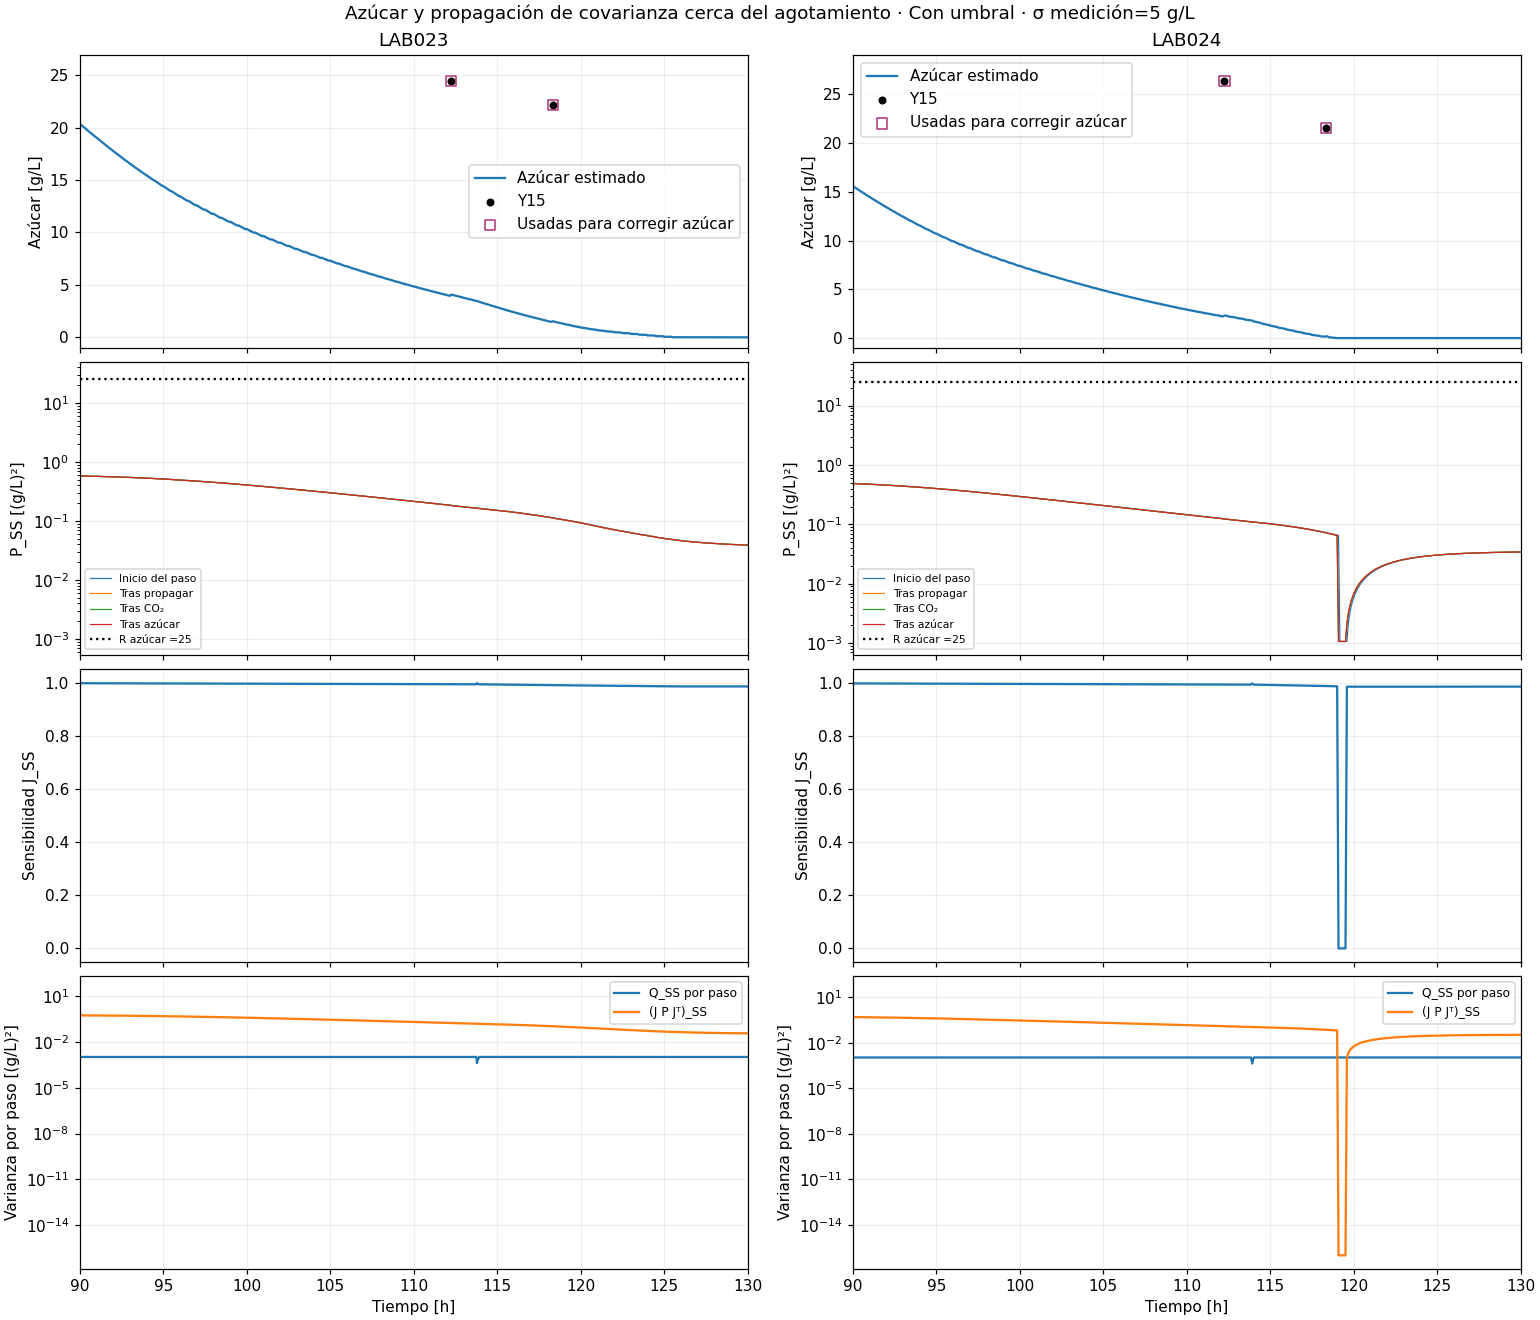

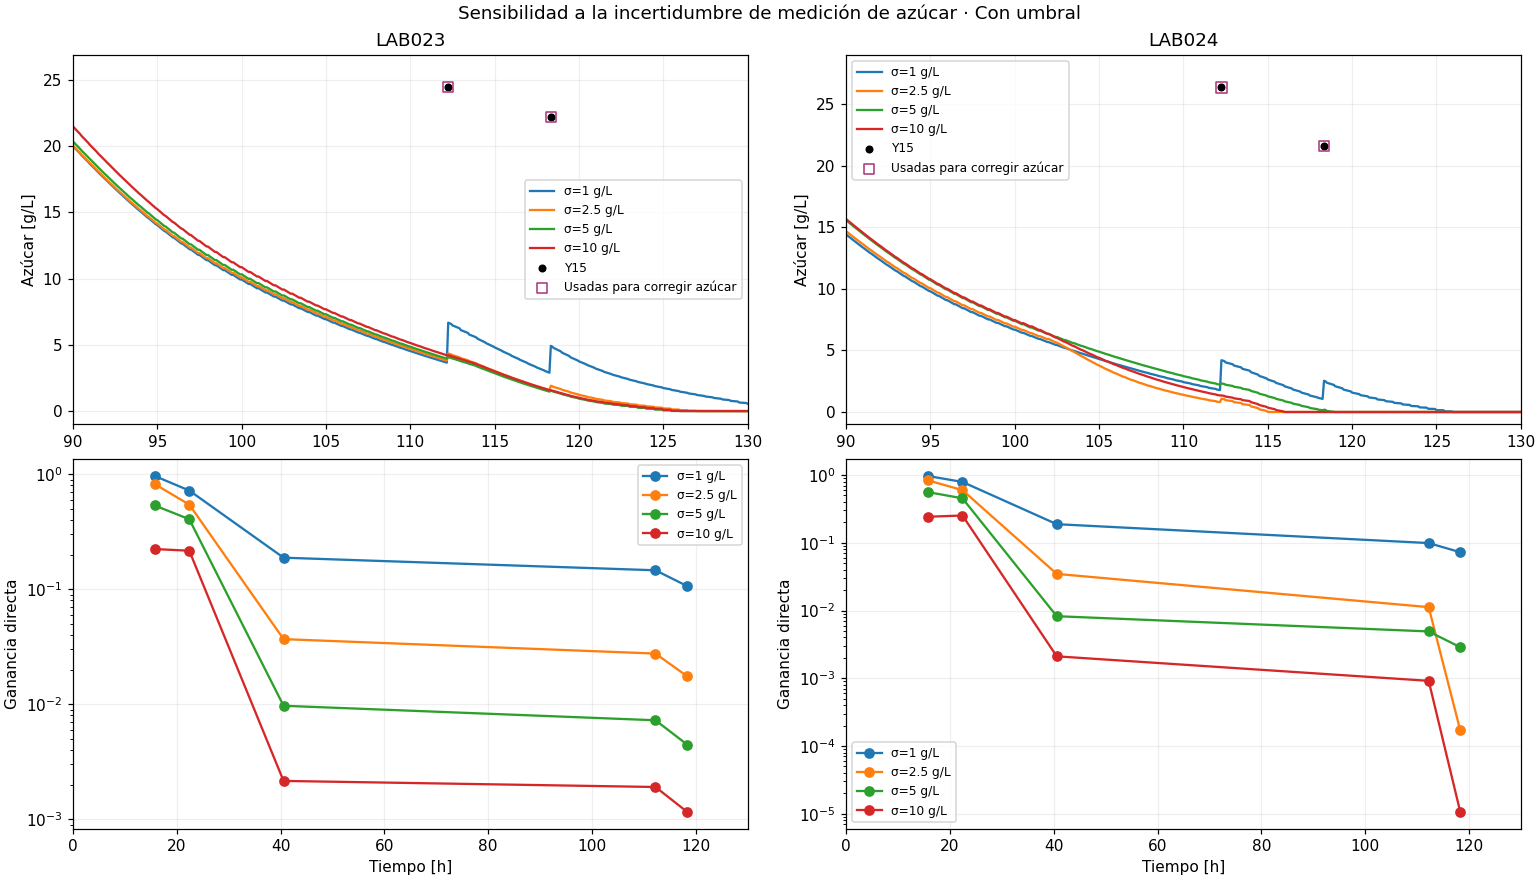

In [27]:
fig,axes=plt.subplots(4,2,figsize=(14,12),layout='constrained',sharex=True)
for col,lab in enumerate(('LAB023','LAB024')):
    _,_,trace,direct=covariance_runs[lab,5.]
    axes[0,col].plot(trace.time,trace.S,label='Azúcar estimado')
    axes[0,col].scatter(direct.time,direct.measured,c='black',s=18,label='Y15')
    axes[0,col].scatter(direct.time,direct.measured,marker='s',facecolors='none',edgecolors='#AA3377',s=45,label='Usadas para corregir azúcar');axes[0,col].set(title=lab,ylabel='Azúcar [g/L]');axes[0,col].legend()
    for name,label in [('variance_start','Inicio del paso'),('variance_propagated','Tras propagar'),('variance_after_co2','Tras CO₂'),('variance_final','Tras azúcar')]:
        axes[1,col].semilogy(trace.time,trace[name].clip(lower=1e-16),label=label,lw=.8)
    axes[1,col].axhline(25,c='black',ls=':',label='R azúcar =25');axes[1,col].set_ylabel('P_SS [(g/L)²]');axes[1,col].legend(fontsize=7)
    axes[2,col].plot(trace.time,trace.j_s,label='J_SS');axes[2,col].set_ylabel('Sensibilidad J_SS')
    axes[3,col].semilogy(trace.time,trace.q_s.clip(lower=1e-16),label='Q_SS por paso')
    axes[3,col].semilogy(trace.time,trace.variance_deterministic.clip(lower=1e-16),label='(J P Jᵀ)_SS')
    axes[3,col].set_ylabel('Varianza por paso [(g/L)²]');axes[3,col].legend(fontsize=8)
    for ax in axes[:,col]:ax.set_xlim(90,130);ax.grid(alpha=.2)
    axes[3,col].set_xlabel('Tiempo [h]')
for col,lab in enumerate(('LAB023','LAB024')):
    tr=covariance_runs[lab,5.][2];dd=covariance_runs[lab,5.][3]
    top=max(tr.loc[tr.time.between(90,130),'S'].max(),dd.loc[dd.time.between(90,130),'measured'].max())
    axes[0,col].set_ylim(-1,1.1*top)
fig.suptitle('Azúcar y propagación de covarianza cerca del agotamiento · Con umbral · σ medición=5 g/L');plt.show()
fig,axes=plt.subplots(2,2,figsize=(14,8),layout='constrained')
for col,lab in enumerate(('LAB023','LAB024')):
    for sigma in (1.,2.5,5.,10.):
        _,_,trace,direct=covariance_runs[lab,sigma]
        axes[0,col].plot(trace.time,trace.S,label=f'σ={sigma:g} g/L')
        axes[1,col].semilogy(direct.time,direct.gain_direct,'o-',label=f'σ={sigma:g} g/L')
    axes[0,col].scatter(direct.time,direct.measured,c='black',s=18,label='Y15')
    axes[0,col].scatter(direct.time,direct.measured,marker='s',facecolors='none',edgecolors='#AA3377',s=45,label='Usadas para corregir azúcar')
    axes[0,col].set(title=lab,xlim=(90,130),ylabel='Azúcar [g/L]')
    axes[1,col].set(xlim=(0,130),ylabel='Ganancia directa',xlabel='Tiempo [h]')
    for ax in axes[:,col]:ax.grid(alpha=.2);ax.legend(fontsize=8)
for col,lab in enumerate(('LAB023','LAB024')):
    top=max(covariance_runs[lab,5.][3].loc[lambda f:f.time.between(90,130),'measured'].max(),1)
    axes[0,col].set_ylim(-1,1.1*top)
fig.suptitle('Sensibilidad a la incertidumbre de medición de azúcar · Con umbral');plt.show()


## Interpretación de la covarianza y de los 5 g/L · CO₂ con umbral

Los resultados siguientes se recalculan con umbral; reemplazan las cifras anteriores obtenidas sin umbral. A las últimas mediciones de LAB023–024, con una desviación de medición de 5 g/L:

| Lote | Hora [h] | Azúcar previo [g/L] | Y15 [g/L] | Varianza previa [(g/L)²] | Desviación del estado [g/L] | Ganancia directa | Azúcar posterior [g/L] |
|---|---:|---:|---:|---:|---:|---:|---:|
| LAB023 | 118.333 | 1.440320 | 22.18 | 0.11224251 | 0.335026 | 0.00446963 | 1.533019 |
| LAB024 | 118.333 | 0.125188 | 21.57 | 0.07211453 | 0.268541 | 0.00287628 | 0.186869 |

En LAB023, la varianza del azúcar parte de 25 y alcanza 13.392712 (g/L)² después de la primera muestra posterior a la inicial (15.750 h). En el primer paso con azúcar prácticamente cero después de 90 h (126.000 h), la sensibilidad J_SS es 0.985509, la contribución (J P Jᵀ)_SS es 0.04517580 y Q_SS añade 0.00106667 (g/L)². Al repetir toda la corrida con una incertidumbre de medición de 1 g/L, la última actualización deja 4.919 g/L, frente a 1.533 g/L con 5 g/L.

En LAB024, la varianza del azúcar parte de 25 y alcanza 14.035378 (g/L)² después de la primera muestra posterior a la inicial (15.750 h). En el primer paso con azúcar prácticamente cero después de 90 h (119.000 h), la sensibilidad J_SS es 0.985858, la contribución (J P Jᵀ)_SS es 0.06414121 y Q_SS añade 0.00106667 (g/L)². Al repetir toda la corrida con una incertidumbre de medición de 1 g/L, la última actualización deja 2.531 g/L, frente a 0.187 g/L con 5 g/L.

Con umbral no se reproduce la contracción extrema antes de la primera muestra que aparecía sin umbral: hasta 15,75 h no hay actualizaciones de CO₂ en estos dos lotes. Las primeras muestras de azúcar reciben ganancias de 0,536 en LAB023 y 0,561 en LAB024. Las posteriores actualizaciones de CO₂ sí reducen la covarianza; a las 40,583 h la desviación previa del azúcar ya es de aproximadamente 0,50 y 0,46 g/L, respectivamente.

En LAB024, con 5 g/L, la anulación de J_SS y de la contribución propagada aparece a las 119,083 h, después de la última muestra de azúcar de 118,333 h. Por tanto, esa anulación no explica por sí sola la pequeña ganancia de esa muestra: antes de llegar a cero el filtro ya le asigna poco peso. La desviación previa a esa última muestra es 0,269 g/L, no los 0,033 g/L de la prueba anterior sin umbral. En LAB023 no se observa esa anulación en el tramo de 90–130 h. En LAB024 la covarianza se recupera parcialmente después de la caída; no queda permanentemente fijada en su mínimo. El momento de agotamiento y la recuperación dependen de la historia completa de correcciones, como muestran las corridas de sensibilidad.

La matriz de covarianza expresa la confianza interna del filtro, no el error real frente a la concentración de azúcar. Una diferencia grande con Y15 no aumenta automáticamente P. Las actualizaciones indirectas con CO₂ pueden reducir la incertidumbre de azúcar; cerca de la frontera de positividad, una sensibilidad local pequeña también puede eliminar su varianza propagada. Una ganancia muy pequeña implica que la medición de azúcar apenas modifica la estimación, aunque la discrepancia sea grande. Esto es exceso de confianza, no evidencia de divergencia numérica.

La tabla con P previo idéntico muestra el efecto algebraico de cambiar R; las corridas completas con 1, 2,5, 5 y 10 g/L incluyen además historias de estados y covarianzas diferentes. Reducir R por sí solo no garantiza recuperar la concentración observada y no debe elegirse su valor únicamente para acercar las curvas. Queda por justificar la incertidumbre de medición, revisar Q y la consistencia de P frente a los residuos, y auditar la integración y su derivada al agotarse el azúcar. Registrar J_SS y la contribución propagada identifica el comportamiento local, pero no separa por sí solo el efecto del consumo del efecto del recorte a cero.


## Corrección de azúcar · comparación de Rss con CO₂ con umbral

Se comparan **Rss=25 y Rss=7,42 (g/L)²**, equivalentes a desviaciones de 5 y √7,42 ≈2,724 g/L. En ambas corridas se asimilan las mismas mediciones posteriores de azúcar: Y15 en LAB019–024 y densidad convertida en LAB016–018. Se conservan las concentraciones originales, las condiciones iniciales, la química, Q, R de CO₂ y el umbral: dos ventanas consecutivas válidas de 30 minutos con flujo medido ≥0,05 g/(L·h). La muestra inicial solo inicializa; se muestra igual que las otras de su serie. Las muestras posteriores utilizadas se señalan con cuadrados magenta. Se mantiene el supuesto de disponibilidad inmediata del resultado.

Se usa el mismo Rss para los dos orígenes de azúcar en esta comparación controlada; esto no constituye una estimación de incertidumbre de densidad. El error de azúcar se calcula antes de cada actualización. La cola de CO₂ se evalúa desde 130 h sobre todas las ventanas válidas, incluidas las que el umbral no permite asimilar. LAB022 se presenta individualmente por su comportamiento atípico. No se sustituyen los valores de azúcar de LAB022–024 ni se modifica la configuración de las secciones anteriores.


In [30]:
from IPython.display import Markdown

rss_values=(25.,7.42)
rss_runs={};rss_metrics=[];rss_details=[]
for lab in ORDER:
    inp=single['data'][lab]
    tt,vv=lab_samples('S',lab,'S');tt=np.asarray(tt);vv=np.asarray(vv)
    keep=(tt>inp['grid'][0])&(tt<=inp['grid'][-1])&np.isfinite(vv)&(vv>=0)
    samples=dict(zip(np.round(tt[keep],10),vv[keep]))
    run={**inp,'sensor':inp['sensor'].copy(),'grid':np.unique(np.r_[inp['grid'],list(samples)]),'sugar_samples':samples}
    validate_base_rule(run['sensor'].valid.to_numpy(),run['sensor'].measured.to_numpy(),run['sensor']['update'].to_numpy())
    for rss in rss_values:
        states,gas,records,trace,direct=single['replay_covariance'](run,single_model,True,np.sqrt(rss))
        rss_runs[lab,rss]=(run,states,gas,trace,direct)
        assert np.isfinite(states).all() and trace.variance_final.min()>=-1e-10
        np.testing.assert_allclose(direct.correction,direct.gain_direct*(direct.measured-direct.prior),atol=1e-9)
        np.testing.assert_array_equal(gas['update'],run['sensor']['update'])
        valid=gas.valid&gas.t_h.ge(1.);tail=valid&gas.t_h.ge(130.)
        last=direct.iloc[-1]
        rss_metrics.append(dict(LAB=lab,Rss=rss,n_azucar=len(direct),
            RMSE_S_previo=np.sqrt(np.mean((direct.prior-direct.measured)**2)),
            RMSE_CO2=np.sqrt(np.mean((gas.forecast[valid]-gas.measured[valid])**2)),
            RMSE_CO2_cola=np.sqrt(np.mean((gas.forecast[tail]-gas.measured[tail])**2)),
            sesgo_CO2_cola=np.mean(gas.forecast[tail]-gas.measured[tail]),
            ultima_hora=last.time,S_previo=last.prior,S_medido=last.measured,S_posterior=last.posterior,
            correccion_ultima=last.correction,ganancia_ultima=last.gain_direct))
        detail=direct.copy();detail.insert(0,'Rss',rss);detail.insert(0,'LAB',lab);rss_details.append(detail)
        print(lab,'Rss',rss,'completado',flush=True)
    np.testing.assert_array_equal(rss_runs[lab,25.][1][:,1],rss_runs[lab,7.42][1][:,1])
rss_metrics=pd.DataFrame(rss_metrics).set_index(['LAB','Rss'])
rss_details=pd.concat(rss_details,ignore_index=True)
display(rss_metrics.round(6))
rss_changes=rss_metrics.xs(7.42,level='Rss')[['RMSE_S_previo','RMSE_CO2','RMSE_CO2_cola']]-rss_metrics.xs(25.,level='Rss')[['RMSE_S_previo','RMSE_CO2','RMSE_CO2_cola']]
rss_changes.columns=['Cambio RMSE azúcar [g/L]','Cambio RMSE CO₂ [g/(L·h)]','Cambio RMSE cola [g/(L·h)]']
display(rss_changes.round(6))
display(rss_details.loc[rss_details.LAB.isin(['LAB023','LAB024'])].round(8))


LAB019 Rss 25.0 completado
LAB019 Rss 7.42 completado
LAB020 Rss 25.0 completado
LAB020 Rss 7.42 completado
LAB021 Rss 25.0 completado
LAB021 Rss 7.42 completado
LAB016 Rss 25.0 completado
LAB016 Rss 7.42 completado
LAB017 Rss 25.0 completado
LAB017 Rss 7.42 completado
LAB018 Rss 25.0 completado
LAB018 Rss 7.42 completado
LAB022 Rss 25.0 completado
LAB022 Rss 7.42 completado
LAB023 Rss 25.0 completado
LAB023 Rss 7.42 completado
LAB024 Rss 25.0 completado
LAB024 Rss 7.42 completado


n_azucar  RMSE_S_previo  ...  correccion_ultima  ganancia_ultima
LAB    Rss                             ...                                    
LAB019 25.00        11       7.687211  ...          -0.000020         0.001718
       7.42         11       6.547310  ...          -0.000050         0.005723
LAB020 25.00        11       4.877330  ...           0.002568         0.002404
       7.42         11       4.572425  ...           0.007943         0.010069
LAB021 25.00         9       9.965714  ...           0.000146         0.001220
       7.42          9       7.620322  ...           0.000491         0.004095
LAB016 25.00         8       8.113574  ...          -1.152113         0.086269
       7.42          8       6.784550  ...          -1.228255         0.135558
LAB017 25.00         8       3.599893  ...          -0.096873         0.100713
       7.42          8       3.006910  ...           0.449414         0.142375
LAB018 25.00         8       4.870328  ...          -0.541735         0.082069
       7.42          8       2.992273  ...          -0.241308         0.129349
LAB022 25.00         5      18.541788  ...           3.822389         0.124154
       7.42          5      18.220359  ...           5.345036         0.202548
LAB023 25.00         5      13.743386  ...           0.092699         0.004470
       7.42          5      13.666493  ...           0.305646         0.014789
LAB024 25.00         5      15.688297  ...           0.061681         0.002876
       7.42          5      15.545798  ...           0.192991         0.008972

[18 rows x 11 columns]

,Cambio RMSE azúcar [g/L],Cambio RMSE CO₂ [g/(L·h)],Cambio RMSE cola [g/(L·h)]
LAB,,,
LAB019,-1.139901,0.001054,0.001393
LAB020,-0.304904,0.005046,0.021601
LAB021,-2.345391,0.001516,-0.000004
LAB016,-1.329024,0.007148,-0.000176
LAB017,-0.592983,0.014766,0.000010
LAB018,-1.878055,0.010548,0.000116
LAB022,-0.321428,-0.009985,-0.014808
LAB023,-0.076893,-0.000550,-0.000040
LAB024,-0.142499,-0.003330,-0.000000


,LAB,Rss,time,measured,prior,posterior,variance_prior,variance_posterior,sd_prior,R_s,gain_direct,correction,N_after
120,LAB023,25.00,15.750000,149.63,140.783122,145.522469,28.845479,13.392712,5.370799,25.00,0.535708,4.739348,193.185820
121,LAB023,25.00,22.416667,143.22,139.395555,140.950667,17.131823,10.165608,4.139061,25.00,0.406624,1.555112,163.408417
122,LAB023,25.00,40.583333,126.06,126.974887,126.966002,0.245175,0.242794,0.495151,25.00,0.009712,-0.008885,95.052199
123,LAB023,25.00,112.250000,24.43,3.922969,4.071931,0.182927,0.181598,0.427700,25.00,0.007264,0.148962,0.000000
124,LAB023,25.00,118.333333,22.18,1.440320,1.533019,0.112243,0.111741,0.335026,25.00,0.004470,0.092699,31.986927
125,LAB023,7.42,15.750000,149.63,140.783122,147.819908,28.845479,5.901851,5.370799,7.42,0.795398,7.036787,194.948209
126,LAB023,7.42,22.416667,143.22,141.883232,142.592080,8.376296,3.934601,2.894183,7.42,0.530270,0.708847,165.203731
127,LAB023,7.42,40.583333,126.06,126.758242,126.736395,0.239660,0.232162,0.489551,7.42,0.031289,-0.021847,94.888224
128,LAB023,7.42,112.250000,24.43,3.785981,4.269363,0.177906,0.173740,0.421789,7.42,0.023415,0.483382,0.000000
129,LAB023,7.42,118.333333,22.18,1.512445,1.818091,0.111379,0.109732,0.333735,7.42,0.014789,0.305646,33.009555


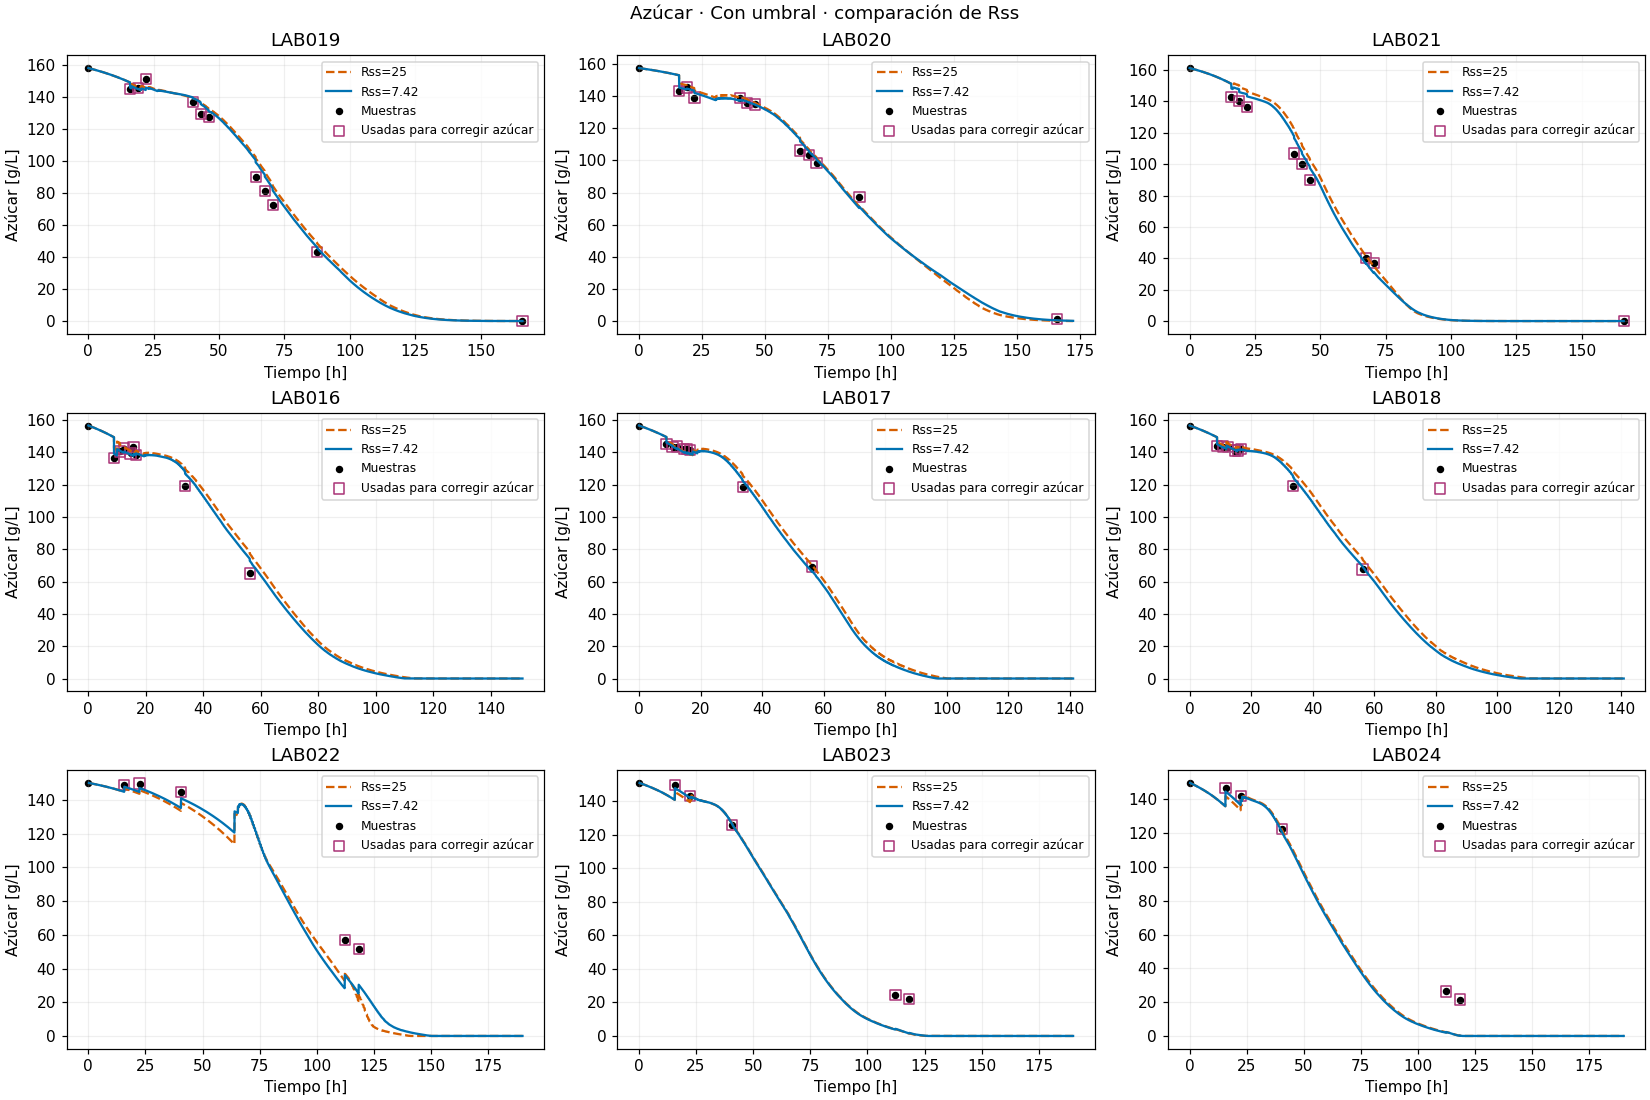

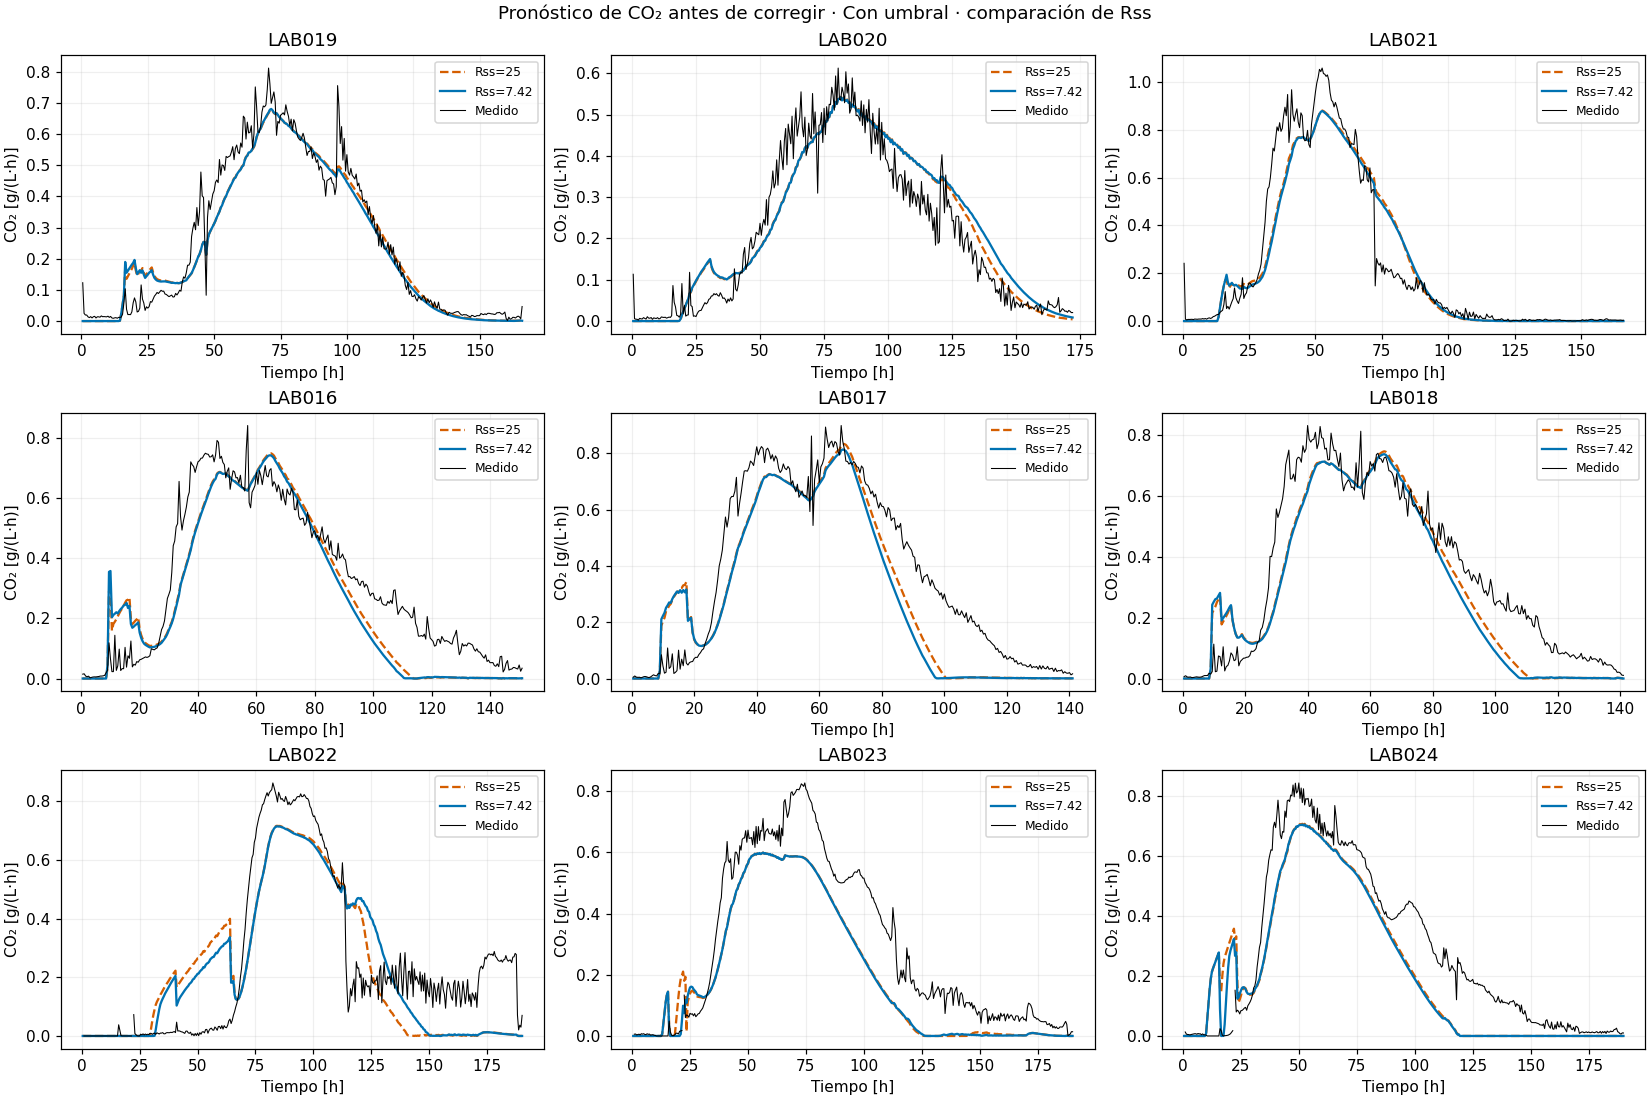

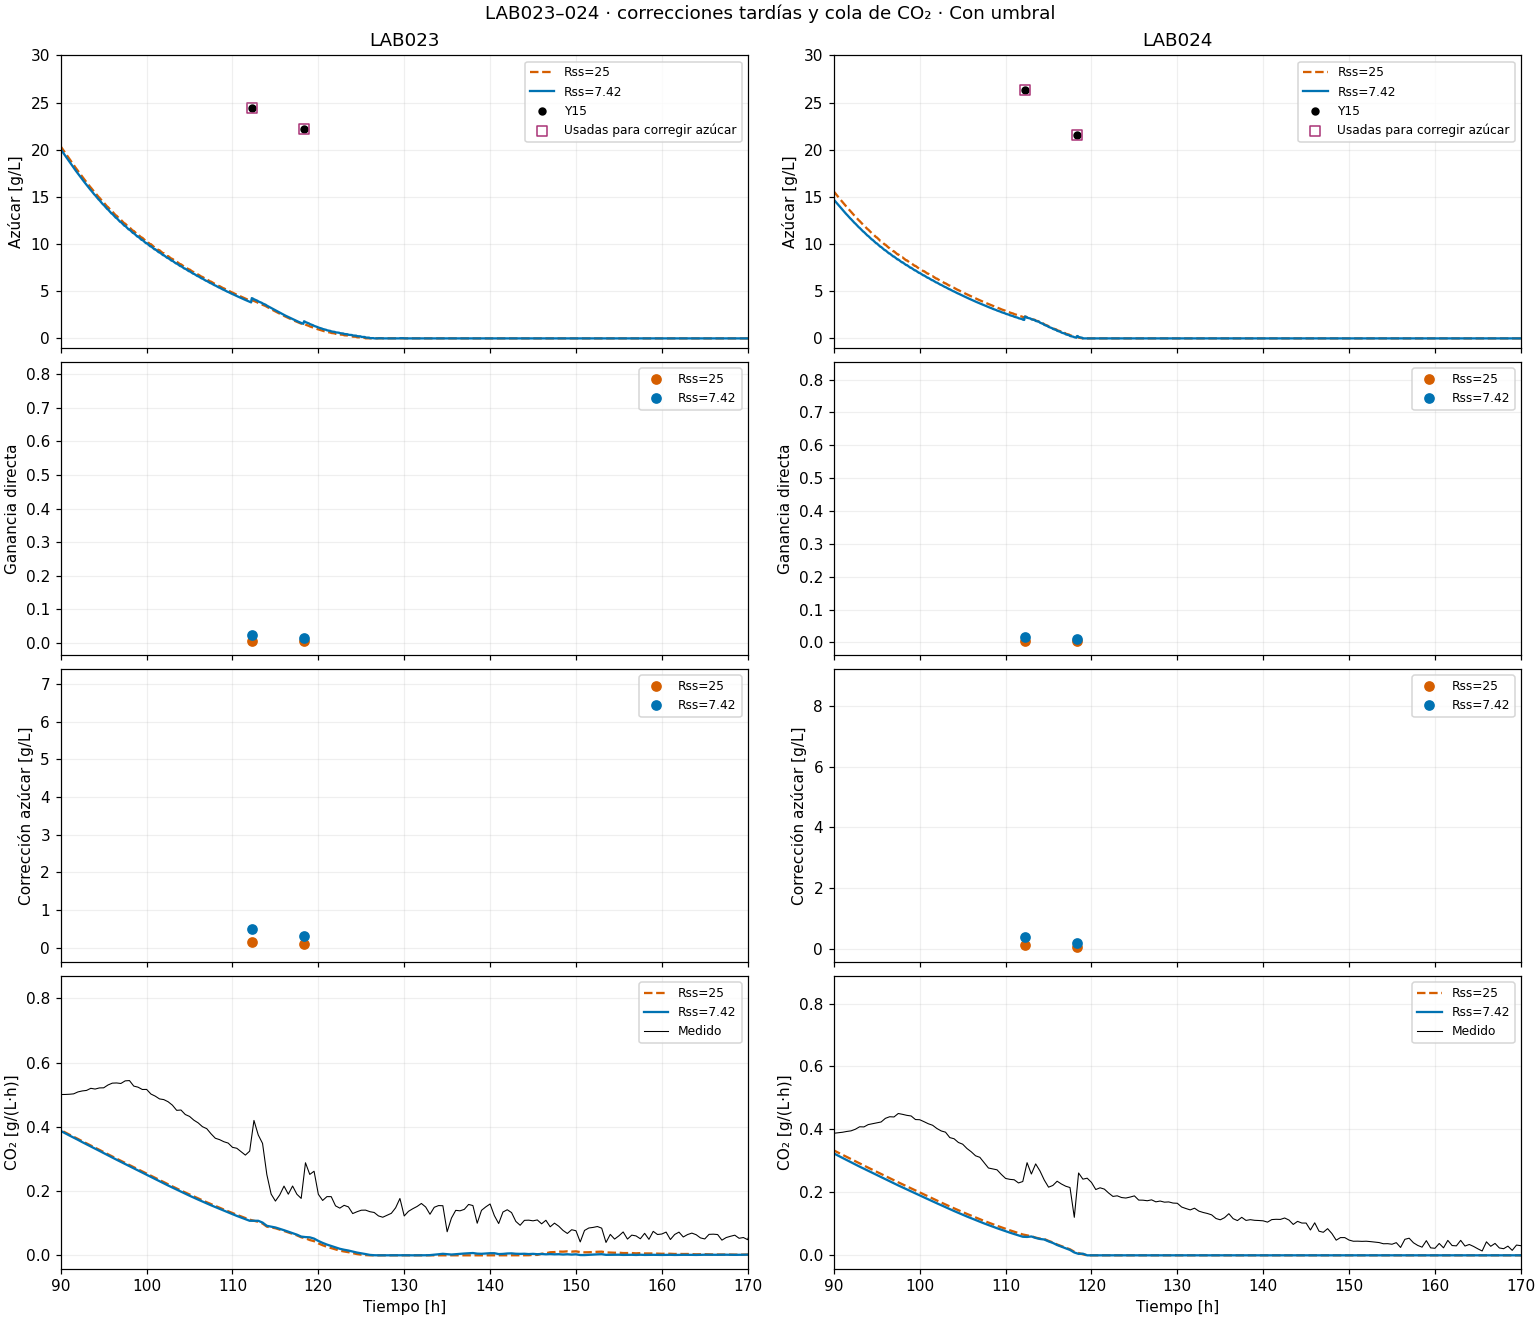

In [31]:
for variable in ('S','CO2'):
    fig,axes=plt.subplots(3,3,figsize=(15,10),layout='constrained')
    for ax,lab in zip(axes.flat,ORDER):
        for rss,color,style in [(25.,'#D55E00','--'),(7.42,'#0072B2','-')]:
            run,states,gas,trace,direct=rss_runs[lab,rss]
            if variable=='S':ax.plot(trace.time,trace.S,color=color,ls=style,label=f'Rss={rss:g}')
            else:ax.plot(gas.t_h,gas.forecast,color=color,ls=style,label=f'Rss={rss:g}')
        if variable=='S':
            tt,vv=lab_samples('S',lab,'S')
            if lab in ('LAB016','LAB017','LAB018'):
                d=density_points[lab];tt=np.r_[d['initial_time'],d['times']];vv=np.r_[d['initial_sugar'],d['sugar']]
            ax.scatter(tt,vv,color='black',s=15,label='Muestras')
            ax.scatter(direct.time,direct.measured,marker='s',facecolors='none',edgecolors='#AA3377',s=45,label='Usadas para corregir azúcar')
        else:ax.plot(gas.t_h,gas.measured.where(gas.valid),color='black',lw=.7,label='Medido')
        ax.set(title=lab,xlabel='Tiempo [h]',ylabel='Azúcar [g/L]' if variable=='S' else 'CO₂ [g/(L·h)]')
        ax.grid(alpha=.2);ax.legend(fontsize=8)
    fig.suptitle(('Azúcar' if variable=='S' else 'Pronóstico de CO₂ antes de corregir')+' · Con umbral · comparación de Rss')
    plt.show()

fig,axes=plt.subplots(4,2,figsize=(14,12),layout='constrained',sharex=True)
for col,lab in enumerate(('LAB023','LAB024')):
    for rss,color,style in [(25.,'#D55E00','--'),(7.42,'#0072B2','-')]:
        _,_,gas,trace,direct=rss_runs[lab,rss]
        axes[0,col].plot(trace.time,trace.S,color=color,ls=style,label=f'Rss={rss:g}')
        axes[1,col].plot(direct.time,direct.gain_direct,'o',color=color,label=f'Rss={rss:g}')
        axes[2,col].plot(direct.time,direct.correction,'o',color=color,label=f'Rss={rss:g}')
        axes[3,col].plot(gas.t_h,gas.forecast,color=color,ls=style,label=f'Rss={rss:g}')
    axes[0,col].scatter(direct.time,direct.measured,color='black',s=20,label='Y15')
    axes[0,col].scatter(direct.time,direct.measured,marker='s',facecolors='none',edgecolors='#AA3377',s=45,label='Usadas para corregir azúcar')
    axes[0,col].set(title=lab,ylabel='Azúcar [g/L]',ylim=(-1,30))
    axes[1,col].set_ylabel('Ganancia directa')
    axes[2,col].set_ylabel('Corrección azúcar [g/L]')
    axes[3,col].plot(gas.t_h,gas.measured.where(gas.valid),color='black',lw=.7,label='Medido')
    axes[3,col].set(ylabel='CO₂ [g/(L·h)]',xlabel='Tiempo [h]')
    for ax in axes[:,col]:ax.set_xlim(90,170);ax.grid(alpha=.2);ax.legend(fontsize=8)
fig.suptitle('LAB023–024 · correcciones tardías y cola de CO₂ · Con umbral')
plt.show()


In [32]:
lines=['## Resultado de comparar Rss=25 y Rss=7,42','',
    'Las siguientes cifras proceden de corridas completas con CO₂ con umbral y corrección de azúcar. Cambiar Rss también modifica la historia de estados y covarianzas; la ganancia final no cambia solo por un factor algebraico.','']
for lab in ('LAB020','LAB023','LAB024'):
    a=rss_metrics.loc[lab,25.];b=rss_metrics.loc[lab,7.42]
    lines.append(f'**{lab}:** el error de azúcar antes de las muestras pasa de {a.RMSE_S_previo:.3f} a {b.RMSE_S_previo:.3f} g/L; el error de CO₂ en la cola desde 130 h pasa de {a.RMSE_CO2_cola:.6f} a {b.RMSE_CO2_cola:.6f} g/(L·h). A las {b.ultima_hora:.3f} h, la medición es {b.S_medido:.3f} g/L: la corrección pasa de {a.correccion_ultima:.6f} a {b.correccion_ultima:.6f} g/L y el azúcar posterior de {a.S_posterior:.6f} a {b.S_posterior:.6f} g/L. Las ganancias son {a.ganancia_ultima:.6f} y {b.ganancia_ultima:.6f}, respectivamente.')
    lines.append('')
lines+=['LAB022 se interpreta individualmente; los resultados de cada laboratorio se conservan en la tabla, sin promediarlo con los demás.',
    '', 'Rss=7,42 equivale a una desviación de 2,724 g/L, no a 7,42 g/L. Estos resultados no recalibran la química ni justifican por sí solos una incertidumbre para densidad. Las muestras incorporadas no constituyen validación independiente y no se han reemplazado sus valores.']
lines += ['', 'En LAB023–024, reducir Rss aumenta las correcciones tardías, pero estas siguen siendo menores que 1 g/L frente a discrepancias de alrededor de 20 g/L; las colas de CO₂ prácticamente no mejoran. En LAB020 disminuye ligeramente el error de azúcar, pero aumenta el error de la cola de CO₂. Reducir solo Rss no resuelve el agotamiento prematuro en LAB023–024.']
display(Markdown('\n'.join(lines)))


## Resultado de comparar Rss=25 y Rss=7,42

Las siguientes cifras proceden de corridas completas con CO₂ con umbral y corrección de azúcar. Cambiar Rss también modifica la historia de estados y covarianzas; la ganancia final no cambia solo por un factor algebraico.

**LAB020:** el error de azúcar antes de las muestras pasa de 4.877 a 4.572 g/L; el error de CO₂ en la cola desde 130 h pasa de 0.035257 a 0.056858 g/(L·h). A las 166.000 h, la medición es 1.350 g/L: la corrección pasa de 0.002568 a 0.007943 g/L y el azúcar posterior de 0.284053 a 0.569092 g/L. Las ganancias son 0.002404 y 0.010069, respectivamente.

**LAB023:** el error de azúcar antes de las muestras pasa de 13.743 a 13.666 g/L; el error de CO₂ en la cola desde 130 h pasa de 0.083472 a 0.083431 g/(L·h). A las 118.333 h, la medición es 22.180 g/L: la corrección pasa de 0.092699 a 0.305646 g/L y el azúcar posterior de 1.533019 a 1.818091 g/L. Las ganancias son 0.004470 y 0.014789, respectivamente.

**LAB024:** el error de azúcar antes de las muestras pasa de 15.688 a 15.546 g/L; el error de CO₂ en la cola desde 130 h pasa de 0.069146 a 0.069146 g/(L·h). A las 118.333 h, la medición es 21.570 g/L: la corrección pasa de 0.061681 a 0.192991 g/L y el azúcar posterior de 0.186869 a 0.252225 g/L. Las ganancias son 0.002876 y 0.008972, respectivamente.

LAB022 se interpreta individualmente; los resultados de cada laboratorio se conservan en la tabla, sin promediarlo con los demás.

Rss=7,42 equivale a una desviación de 2,724 g/L, no a 7,42 g/L. Estos resultados no recalibran la química ni justifican por sí solos una incertidumbre para densidad. Las muestras incorporadas no constituyen validación independiente y no se han reemplazado sus valores.

En LAB023–024, reducir Rss aumenta las correcciones tardías, pero estas siguen siendo menores que 1 g/L frente a discrepancias de alrededor de 20 g/L; las colas de CO₂ prácticamente no mejoran. En LAB020 disminuye ligeramente el error de azúcar, pero aumenta el error de la cola de CO₂. Reducir solo Rss no resuelve el agotamiento prematuro en LAB023–024.